<a href="https://colab.research.google.com/github/SOUHARDGUPTA/Speech-To-Face-Generation-/blob/main/S2F_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os

folders = [
    "Speech-to-face/src/models",
    "Speech-to-face/src/datasets",
    "Speech-to-face/src/data_preprocessing",
    "Speech-to-face/src/inference",
    "Speech-to-face/src/train",
    "Speech-to-face/src/tensorflow_to_pytorch"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


In [ ]:
%%writefile Speech-to-face/src/models/face_decoder.py
import torch.nn as nn


class FaceDecoder(nn.Module):
    """
    Input to the model should be face embedding vector of dimension equal to 4096
    """
    def __init__(self):
        super(FaceDecoder, self).__init__()
        self.pre_layers = self.define_pre_layers()
        self.landmark_layers = self.define_landmark_layers()
        self.texture_layers = self.define_texture_layers()


    def define_pre_layers(self):
        layers = nn.ModuleList()
        pre_layer1 = nn.Sequential(
            nn.Linear(in_features=4096, out_features=3072),
            nn.BatchNorm1d(num_features=3072),
            nn.ReLU()
        )
        layers.append(pre_layer1)

        pre_layer2 = nn.Sequential(
            nn.Linear(in_features=3072, out_features=2048),
            nn.BatchNorm1d(num_features=2048),
            nn.ReLU()
        )
        layers.append(pre_layer2)

        return layers


    def define_landmark_layers(self):
        layers = nn.ModuleList()
        landmark_layer1 = nn.Sequential(
            nn.Linear(in_features=2048, out_features=1024),
            nn.BatchNorm1d(num_features=1024),
            nn.ReLU()
        )
        layers.append(landmark_layer1)

        landmark_layer2 = nn.Sequential(
            nn.Linear(in_features=1024, out_features=512),
            nn.BatchNorm1d(num_features=512),
            nn.ReLU()
        )
        layers.append(landmark_layer2)

        landmark_layer3 = nn.Sequential(
            nn.Linear(in_features=512, out_features=256),
            nn.BatchNorm1d(num_features=256),
            nn.ReLU()
        )
        layers.append(landmark_layer3)

        landmark_layer4 = nn.Sequential(
            nn.Linear(in_features=256, out_features=144),
        )
        layers.append(landmark_layer4)

        return layers


    def define_texture_layers(self):
        layers = nn.ModuleList()
        texture_layer1 = nn.Sequential(
            nn.Linear(in_features=2048, out_features=256 * 14 * 14),
            nn.ReLU()
        )
        layers.append(texture_layer1)

        texture_layer2 = nn.Sequential(
            nn.Unflatten(dim=1, unflattened_size=(256, 14, 14)),
            nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=5, stride=2, padding=2, output_padding=1),
            nn.ReLU()
        )
        layers.append(texture_layer2)

        texture_layer3 = nn.Sequential(
            nn.ConvTranspose2d(in_channels=128, out_channels=64, kernel_size=5, stride=2, padding=2, output_padding=1),
            nn.ReLU()
        )
        layers.append(texture_layer3)

        texture_layer4 = nn.Sequential(
            nn.ConvTranspose2d(in_channels=64, out_channels=32, kernel_size=5, stride=2, padding=2, output_padding=1),
            nn.ReLU()
        )
        layers.append(texture_layer4)

        texture_layer5 = nn.Sequential(
            nn.ConvTranspose2d(in_channels=32, out_channels=32, kernel_size=5, stride=2, padding=2, output_padding=1),
            nn.ReLU()
        )
        layers.append(texture_layer5)

        texture_layer6 = nn.Sequential(
            nn.Conv2d(in_channels=32, out_channels=3, kernel_size=1, stride=1),
            nn.Sigmoid()
        )
        layers.append(texture_layer6)

        return layers


    def forward(self, x):
        for pre_layer in self.pre_layers:
            x = pre_layer(x)

        landmarks = x
        for landmark_layer in self.landmark_layers:
            landmarks = landmark_layer(landmarks)

        texture = x
        for texture_layer in self.texture_layers:
            texture = texture_layer(texture)

        return landmarks, texture

    def get_predifined_layer_activation(self, x):
        for pre_layer in self.pre_layers:
            x = pre_layer(x)
        return x

Writing Speech-to-face/src/models/face_decoder.py


In [ ]:
%%writefile Speech-to-face/src/models/face_encoder.py
import torch
import torch.nn as nn


class VGGFace_serengil(nn.Module):
    """
    Input to the model should be an image of size 224x224 and 3 channels
    """
    def __init__(self):
        super(VGGFace_serengil, self).__init__()

        self.layers = []

        self.layer1 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=3, out_channels=64, kernel_size=(3,3), stride=1),
            nn.ReLU()
        )
        self.layers.append(self.layer1)

        self.layer2 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,3), stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer2)

        self.layer3 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=(3,3), stride=1),
            nn.ReLU()
        )
        self.layers.append(self.layer3)

        self.layer4 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=(3,3), stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer4)

        self.layer5 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=(3,3), stride=1),
            nn.ReLU()
        )
        self.layers.append(self.layer5)

        self.layer6 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=(3,3), stride=1),
            nn.ReLU()
        )
        self.layers.append(self.layer6)

        self.layer7 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=(3,3), stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer7)

        self.layer8 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=256, out_channels=512, kernel_size=(3,3), stride=1),
            nn.ReLU()
        )
        self.layers.append(self.layer8)

        self.layer9 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1),
            nn.ReLU()
        )
        self.layers.append(self.layer9)

        self.layer10 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer10)

        self.layer11 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1),
            nn.ReLU()
        )
        self.layers.append(self.layer11)

        self.layer12 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1),
            nn.ReLU()
        )
        self.layers.append(self.layer12)

        self.layer13 = nn.Sequential(
            nn.ZeroPad2d(padding=1),
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer13)

        self.layer14 = nn.Sequential(
            nn.Conv2d(in_channels=512, out_channels=4096, kernel_size=(7,7), stride=1),
            nn.ReLU(),
            nn.Dropout(p=0.5)
        )
        self.layers.append(self.layer14)

        self.layer15 = nn.Sequential(
            nn.Conv2d(in_channels=4096, out_channels=4096, kernel_size=(1,1), stride=1),
            nn.ReLU()
        )
        self.layers.append(self.layer15)

        self.layer16 = nn.Sequential(
            nn.Dropout(p=0.5),
            nn.Conv2d(in_channels=4096, out_channels=2622, kernel_size=(1,1), stride=1),
            nn.Flatten()
        )
        self.layers.append(self.layer16)

    def forward(self, x, get_embedding=False):
        for i in range(len(self.layers) - 1):
            x = self.layers[i](x)

        if get_embedding is False:
            x = self.layers[-1](x)
        else:
            x = nn.Flatten()(x)

        return x

    def get_last_layer_activation(self, input):
        input = input.unsqueeze(2).unsqueeze(3)
        return self.layers[-1](input)


class VGGFace16_rcmalli(nn.Module):
    """
    Input to the model should be an image of size 224x224 and 3 channels
    """
    def __init__(self):
        super(VGGFace16_rcmalli, self).__init__()

        self.layers = []

        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=64, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU()
        )
        self.layers.append(self.layer1)

        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer2)

        self.layer3 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU()
        )
        self.layers.append(self.layer3)

        self.layer4 = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer4)

        self.layer5 = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU()
        )
        self.layers.append(self.layer5)

        self.layer6 = nn.Sequential(
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU()
        )
        self.layers.append(self.layer6)

        self.layer7 = nn.Sequential(
            nn.Conv2d(in_channels=256, out_channels=256, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer7)

        self.layer8 = nn.Sequential(
            nn.Conv2d(in_channels=256, out_channels=512, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU()
        )
        self.layers.append(self.layer8)

        self.layer9 = nn.Sequential(
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU()
        )
        self.layers.append(self.layer9)

        self.layer10 = nn.Sequential(
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer10)

        self.layer11 = nn.Sequential(
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU()
        )
        self.layers.append(self.layer11)

        self.layer12 = nn.Sequential(
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU()
        )
        self.layers.append(self.layer12)

        self.layer13 = nn.Sequential(
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=(3,3), stride=1, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        )
        self.layers.append(self.layer13)

        self.layer14 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=25088, out_features=4096),
            nn.ReLU()
        )
        self.layers.append(self.layer14)

        self.layer15 = nn.Sequential(
            nn.Linear(in_features=4096, out_features=4096),
            nn.ReLU()
        )
        self.layers.append(self.layer15)

        self.layer16 = nn.Sequential(
            nn.Linear(in_features=4096, out_features=2622)
        )
        self.layers.append(self.layer16)

    def forward(self, x, get_embedding=False):
        for i in range(len(self.layers) - 1):
            x = self.layers[i](x)
        if get_embedding is False:
            x = self.layers[-1](x)
        return x

    def get_last_layer_activation(self, input):
        return self.layers[-1](input)

Writing Speech-to-face/src/models/face_encoder.py


In [ ]:
%%writefile Speech-to-face/src/models/voice_encoder.py
import torch.nn as nn


class VE_conv(nn.Module):
    """
    Input to the model should be an spectrogram calculated from an audio file 6 seconds - with shape (2, 257, 601)
    """
    def __init__(self):
        super(VE_conv, self).__init__()

        self.layers = []

        self.layer1 = nn.Sequential(
            nn.Conv2d(in_channels=2, out_channels=64, kernel_size=4, stride=1),
            nn.ReLU(),
            nn.BatchNorm2d(64)
        )
        self.layers.append(self.layer1)

        self.layer2 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=64, kernel_size=4, stride=1),
            nn.ReLU(),
            nn.BatchNorm2d(64)
        )
        self.layers.append(self.layer2)

        self.layer3 = nn.Sequential(
            nn.Conv2d(in_channels=64, out_channels=128, kernel_size=4, stride=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2))
        )
        self.layers.append(self.layer3)

        self.layer4 = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=4, stride=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2))
        )
        self.layers.append(self.layer4)

        self.layer5 = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=128, kernel_size=4, stride=1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2))
        )
        self.layers.append(self.layer5)

        self.layer6 = nn.Sequential(
            nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4, stride=1),
            nn.ReLU(),
            nn.BatchNorm2d(256),
            nn.MaxPool2d(kernel_size=(1, 2), stride=(1, 2))
        )
        self.layers.append(self.layer6)

        self.layer7 = nn.Sequential(
            nn.Conv2d(in_channels=256, out_channels=512, kernel_size=4, stride=1),
            nn.ReLU(),
            nn.BatchNorm2d(512)
        )
        self.layers.append(self.layer7)

        self.layer8 = nn.Sequential(
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=4, stride=2),
            nn.ReLU(),
            nn.BatchNorm2d(512)
        )
        self.layers.append(self.layer8)

        self.layer9 = nn.Sequential(
            nn.Conv2d(in_channels=512, out_channels=512, kernel_size=4, stride=2),
            nn.AdaptiveAvgPool2d((None, 1)),
            nn.ReLU(),
            nn.BatchNorm2d(512)
        )
        self.layers.append(self.layer9)

        self.layer10 = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=29184, out_features=4096),
            nn.ReLU()
        )
        self.layers.append(self.layer10)

        self.layer11 = nn.Sequential(
            nn.Linear(in_features=4096, out_features=4096),
            nn.ReLU()
        )
        self.layers.append(self.layer11)


    def forward(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

Writing Speech-to-face/src/models/voice_encoder.py


In [ ]:
!ls Speech-to-face/src/models

face_decoder.py  face_encoder.py  voice_encoder.py


In [ ]:
%%writefile Speech-to-face/src/datasets/face_decoder_dataset.py
import os
import numpy as np
from PIL import Image
from PIL import ImageOps
from torch.utils.data import Dataset
import torchvision.transforms as transforms


class FaceDecoderDataset(Dataset):
    def __init__(self, root_folder, transform=None, target_transform=None):
        self.root_folder = root_folder
        if transform is None:
            self.transform = transforms.Compose([
                transforms.Resize((224, 224)),
                transforms.ToTensor()
            ])
        else:
            self.transform = transform
        self.target_transform = target_transform
        self.data_paths = self.find_paths()
        self.individuals_number = len(self.data_paths)

    def find_paths(self):
        paths = []
        for person_dir in os.listdir(self.root_folder):
            person_list = []
            person_path = os.path.join(self.root_folder, person_dir)
            for root, _, files in os.walk(person_path):
                for file_name in files:
                    base, extension = os.path.splitext(file_name)
                    # For each image in dataset, there must be embedding and landmarks file
                    if extension != '.jpg' or \
                        not os.path.isfile(os.path.join(root, f"{base}_landmarks.npy")) or \
                        not os.path.isfile(os.path.join(root, f"{base}_embedding.npy")):
                        continue
                    image_path = os.path.join(root, base)
                    person_list.append(image_path)
            paths.append(person_list)
        return paths

    def __len__(self):
        length = 0
        for i in range(self.individuals_number):
            length += len(self.data_paths[i])
        return length

    def __getitem__(self, idx):
        person_idx = -1
        data_idx = -1
        start_idx = 0
        for i in range(self.individuals_number):
            num_elems = len(self.data_paths[i])
            if idx >= start_idx and idx < start_idx + num_elems:
                idx -= start_idx
                data_idx = idx
                person_idx = i
                break
            start_idx += num_elems
        image_path = f"{self.data_paths[person_idx][data_idx]}.jpg"
        embedding_path = f"{self.data_paths[person_idx][data_idx]}_embedding.npy"
        landmarks_path = f"{self.data_paths[person_idx][data_idx]}_landmarks.npy"
        image = Image.open(str(image_path))
        image = ImageOps.exif_transpose(image)
        image = self.transform(image)
        embedding = np.load(embedding_path)
        landmarks = np.load(landmarks_path)
        return image, embedding, landmarks

Writing Speech-to-face/src/datasets/face_decoder_dataset.py


In [ ]:
%%writefile Speech-to-face/src/datasets/face_decoder_dataset_split.py
import os
from argparse import ArgumentParser
from sklearn.model_selection import train_test_split
from deepface import DeepFace
import pandas as pd
from tqdm import tqdm
import shutil
from statistics import mean


ACCEPTED_IMAGE_EXTENSIONS = ['.jpg']

parser = ArgumentParser(description="Spliting FaceDecoderDataset into train/val/test sets but \
                        in a way that each set contains the same ration for race, age group and gender")

parser.add_argument("--dataset-path", type=str, required=True,
                    help="Path to the root folder of the whole dataset")

parser.add_argument("--save-path", type=str, required=True,
                    help="Path to the root folder where train/validation/test splits will be saved")

parser.add_argument("--train-size", type=float, default=0.8,
                    help="Proportion of the dataset to include in train split (should be between 0.0 and 1.0) \
                        test and validation set sizes are the same")

parser.add_argument("--race", action="store_true",
                    help="Set if you want to stratify dataseet based on people's race")

parser.add_argument("--age", action="store_true",
                    help="Set if you want to stratify dataseet based on people's age")

parser.add_argument("--gender", action="store_true",
                    help="Set if you want to stratify dataseet based on people's gender")


def save_set(set, split_type, args):
    for row in set.iterrows():
        person_directory_name = os.path.basename(os.path.normpath(row[1]["path"]))
        src_path = os.path.join(args.dataset_path, person_directory_name)
        dest_path = os.path.join(args.save_path, split_type, person_directory_name)
        shutil.copytree(src_path, dest_path)


def get_age_group(age):
    age_groups = {
        # Group Name and and the age from which one is included in that group
        "Child": 0,
        "YoungAdult": 18,
        "MiddleAgedAdult": 30,
        "OldAgedAdults": 45
    }
    selected_key = ""
    for key, value in age_groups.items():
        if age < value:
            break
        selected_key = key
    assert selected_key != ""
    return selected_key


def analyze_image(file_path, actions):
    try:
        analysis = DeepFace.analyze(file_path, actions=actions)
        analysis = analysis[0]
    except ValueError as e:
        # if Face was not detected, return default values
        return {
            "age": 35,
            "dominant_race": "white",
            "dominant_gender": "Man"
        }
    return analysis


def analyze_person(person_folder, actions, args):
    """
    Determine statistics of the person basing on all of images in this person's directory
    """
    person_statistics = {
        "age_groups": [],
        "races": [],
        "genders": []
    }
    for file_name in os.listdir(person_folder):
        file_path = os.path.join(person_folder, file_name)
        if os.path.isfile(file_path):
            _, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_IMAGE_EXTENSIONS:
                continue
            analysis = analyze_image(file_path, actions)
            if args.age:
                person_statistics["age_groups"].append(analysis["age"])
            if args.race:
                person_statistics["races"].append(analysis["dominant_race"])
            if args.gender:
                person_statistics["genders"].append(analysis["dominant_gender"])

    processed_person = {
        "path": person_folder,
        "age_group": get_age_group(mean(person_statistics["age_groups"])) if args.age else "NaN",
        "race": max(person_statistics["races"], key=person_statistics["races"].count) if args.race else "NaN",
        "gender": max(person_statistics["genders"], key=person_statistics["genders"].count) if args.gender else "NaN"
    }
    return processed_person


def main():
    args = parser.parse_args()

    actions = []
    if args.age:
        actions.append("age")
    if args.gender:
        actions.append("gender")
    if args.race:
        actions.append("race")

    dataset_rows = []
    for directory_name in tqdm(os.listdir(args.dataset_path)):
        person_directory = os.path.join(args.dataset_path, directory_name)
        if os.path.isdir(person_directory):
            try:
                dataset_rows.append(analyze_person(person_directory, actions, args))
            except:
                continue

    tagged_dataset_df = pd.DataFrame(dataset_rows)
    tagged_dataset_df["merged_label"] = (tagged_dataset_df["age_group"].astype(str) + "_" if args.age else "_") + \
                                        (tagged_dataset_df["race"].astype(str) + "_" if args.race else "_") + \
                                        (tagged_dataset_df["gender"].astype(str) if args.gender else "_")

    train_set_x, rest_x, _, rest_y = train_test_split(tagged_dataset_df, tagged_dataset_df["merged_label"], random_state=42)
    val_set_x, test_set_x, _, _ = train_test_split(rest_x, rest_y, random_state=42)
    save_set(train_set_x, "train", args)
    save_set(val_set_x, "validation", args)
    save_set(test_set_x, "test", args)


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/datasets/face_decoder_dataset_split.py


In [ ]:
%%writefile Speech-to-face/src/datasets/s2f_dataset_all_to_all.py
import os
from torch.utils.data import Dataset
import numpy as np


class S2fDatasetAlltoAll(Dataset):
    def __init__(self, root_folder, is_ast=False, transform=None, target_transform=None):
        self.root_folder = root_folder
        self.transform = transform
        self.target_transform = target_transform
        self.emebddings_paths = []
        self.spectrograms_paths = []
        self.find_paths()
        self.individuals_number = len(self.emebddings_paths)
        self.is_ast = is_ast

    def find_paths(self):
        for person_dir in os.listdir(self.root_folder):
            spectrogram_path = os.path.join(self.root_folder, person_dir, "audios")
            person_spectrograms = self.get_list_of_data_paths(spectrogram_path)
            embedding_path = os.path.join(self.root_folder, person_dir, "images")
            person_embeddings = self.get_list_of_data_paths(embedding_path)

            if len(person_spectrograms) == 0 or len(person_embeddings) == 0:
                continue # skip identities which does not have spectrograms or embeddings

            self.spectrograms_paths.append(person_spectrograms)
            self.emebddings_paths.append(person_embeddings)

    def get_list_of_data_paths(self, path):
        data_paths = []
        for root, _, files in os.walk(path):
            for file_name in files:
                _, extension = os.path.splitext(file_name)
                if extension != '.npy':
                    continue
                file_path = os.path.join(root, file_name)
                data_paths.append(file_path)
        return data_paths

    def __len__(self):
        length = 0
        for i in range(self.individuals_number):
            length += len(self.emebddings_paths[i]) * len(self.spectrograms_paths[i])
        return length

    def __getitem__(self, idx):
        spectrogram_idx = -1
        embedding_idx = -1
        person_idx = -1
        start_idx = 0
        for i in range(self.individuals_number):
            num_elems = len(self.emebddings_paths[i]) * len(self.spectrograms_paths[i])
            if idx >= start_idx and idx < start_idx + num_elems:
                idx -= start_idx
                spectrogram_idx = idx // len(self.emebddings_paths[i])
                embedding_idx = idx % len(self.emebddings_paths[i])
                person_idx = i
                break
            start_idx += num_elems
        spectrogram_path = self.spectrograms_paths[person_idx][spectrogram_idx]
        embedding_path = self.emebddings_paths[person_idx][embedding_idx]
        spectrogram = np.load(spectrogram_path)
        embedding = np.load(embedding_path)
        if self.is_ast:
            spectrogram = spectrogram.squeeze()
        return spectrogram, embedding

Writing Speech-to-face/src/datasets/s2f_dataset_all_to_all.py


In [ ]:
%%writefile Speech-to-face/src/datasets/s2f_dataset_all_to_one.py
import os
from torch.utils.data import Dataset
import numpy as np


class S2fDatasetAllToOne(Dataset):
    def __init__(self, root_folder, is_ast=False, transform=None, target_transform=None, n=-1):
        self.root_folder = root_folder
        self.transform = transform
        self.n = n
        self.target_transform = target_transform
        self.emebddings_paths = []
        self.spectrograms_paths = []
        self.find_paths()
        self.individuals_number = len(self.emebddings_paths)
        self.is_ast = is_ast
        assert len(self.spectrograms_paths) == len(self.emebddings_paths), "Number of spectrograms is not equal to number of embeddings"

    def find_paths(self):
        for person_dir in os.listdir(self.root_folder):
            spectrogram_path = os.path.join(self.root_folder, person_dir, "audios")
            person_spectrograms = self.get_list_of_data_paths(spectrogram_path)
            embedding_path = os.path.join(self.root_folder, person_dir, "images")
            person_embeddings = self.get_list_of_data_paths(embedding_path)

            num_spec = len(person_spectrograms)
            num_emb = len(person_embeddings)
            if num_spec == 0 or num_emb == 0:
                continue # skip identities which does not have spectrograms or embeddings

            if self.n == -1:
                min_number = num_spec
            else:
                min_number = self.n if num_spec > self.n else num_spec

            self.spectrograms_paths += person_spectrograms[:min_number]

            self.emebddings_paths += (min_number * [person_embeddings[0]])
            assert len(self.spectrograms_paths) == len(self.emebddings_paths), "Unexpected number of spectrograms or embeddings (sizes are not equal)"

    def get_list_of_data_paths(self, path):
        data_paths = []
        for root, _, files in os.walk(path):
            for file_name in files:
                _, extension = os.path.splitext(file_name)
                if extension != '.npy':
                    continue
                file_path = os.path.join(root, file_name)
                data_paths.append(file_path)
        return data_paths

    def __len__(self):
        return len(self.emebddings_paths)

    def __getitem__(self, idx):
        spectrogram_path = self.spectrograms_paths[idx]
        embedding_path = self.emebddings_paths[idx]
        spectrogram = np.load(spectrogram_path)
        embedding = np.load(embedding_path)

        if self.is_ast:
            spectrogram = spectrogram.squeeze()
        return spectrogram, embedding

Writing Speech-to-face/src/datasets/s2f_dataset_all_to_one.py


In [ ]:
%%writefile Speech-to-face/src/datasets/s2f_dataset_one_to_one.py
import os
from torch.utils.data import Dataset
import numpy as np


class S2fDatasetOneToOne(Dataset):
    def __init__(self, root_folder, is_ast=False, transform=None, target_transform=None):
        self.root_folder = root_folder
        self.transform = transform
        self.target_transform = target_transform
        self.emebddings_paths = []
        self.spectrograms_paths = []
        self.find_paths()
        self.individuals_number = len(self.emebddings_paths)
        self.is_ast = is_ast
        assert len(self.spectrograms_paths) == len(self.emebddings_paths), "Number of spectrograms is not equal to number of embeddings"

    def find_paths(self):
        for person_dir in os.listdir(self.root_folder):
            spectrogram_path = os.path.join(self.root_folder, person_dir, "audios")
            person_spectrograms = self.get_list_of_data_paths(spectrogram_path)
            embedding_path = os.path.join(self.root_folder, person_dir, "images")
            person_embeddings = self.get_list_of_data_paths(embedding_path)

            num_spec = len(person_spectrograms)
            num_emb = len(person_embeddings)
            if num_spec == 0 or num_emb == 0:
                continue # skip identities which does not have spectrograms or embeddings

            min_number = num_spec if num_spec < num_emb else num_emb
            self.spectrograms_paths += person_spectrograms[:min_number]
            self.emebddings_paths += person_embeddings[:min_number]
            assert len(self.emebddings_paths) == len(self.spectrograms_paths), "Unexpected number of spectrograms or embeddings (sizes are not equal)"

    def get_list_of_data_paths(self, path):
        data_paths = []
        for root, _, files in os.walk(path):
            for file_name in files:
                _, extension = os.path.splitext(file_name)
                if extension != '.npy':
                    continue
                file_path = os.path.join(root, file_name)
                data_paths.append(file_path)
        return data_paths

    def __len__(self):
        return len(self.emebddings_paths)

    def __getitem__(self, idx):
        spectrogram_path = self.spectrograms_paths[idx]
        embedding_path = self.emebddings_paths[idx]
        spectrogram = np.load(spectrogram_path)
        embedding = np.load(embedding_path)
        if self.is_ast:
            spectrogram = spectrogram.squeeze()
        return spectrogram, embedding

Writing Speech-to-face/src/datasets/s2f_dataset_one_to_one.py


In [ ]:
!ls Speech-to-face/src/datasets

face_decoder_dataset.py        s2f_dataset_all_to_one.py
face_decoder_dataset_split.py  s2f_dataset_one_to_one.py
s2f_dataset_all_to_all.py


In [ ]:
%%writefile Speech-to-face/src/data_preprocessing/ast_audio_preprocess.py
from argparse import ArgumentParser
import numpy as np
import librosa
import os
from tqdm import tqdm
import ffmpeg
import subprocess
from transformers import ASTFeatureExtractor
import concurrent.futures


ACCEPTED_AUDIO_EXTENSIONS = ['.m4a', '.wav','.ogg']

parser = ArgumentParser(description="Raw audio to spectogram conversion")

parser.add_argument("--data-dir", required=True, type=str,
                    help="Absolute path to the directory where audio files are located")

parser.add_argument("--save-dir", required=True, type=str,
                    help="Absolute path to the directory where spectrograms will be saved")

parser.add_argument("--audio-length", default=10.26, type=float,
                    help="length of the audio that will be converted to spectogram. Longer audio \
                          files will be clipped, and shorter files will be repeated")

parser.add_argument("--sampling-rate", default=16000, type=int,
                    help="The number of samples per second of audio (for AST it must be 16KHz)")

parser.add_argument("--mean", default=-5.460994, type=float,
                    help="Mean value of the audio files (calculated on the training set)")

parser.add_argument("--std", default=3.1129124, type=float,
                    help="Standard deviation value of the audio files (calculated on the training set)")

parser.add_argument("--num-threads", default=12, type=int,
                    help="Number of threads to process audio")


def normalize_audio(file_path, root, file_base):
    output_path = os.path.join(root, f"{file_base}_normalized.wav")
    ffmpeg.input(file_path).output(output_path, ar=16000, acodec="pcm_s16le", ac=1, loglevel="quiet").run()
    normalize_command = ["ffmpeg-normalize", output_path, "--normalization-type", "rms", "-t", "-23", "-o", output_path, '-f']
    subprocess.run(normalize_command)
    return output_path

def stretch_audio(args, waveform):
    duration = librosa.get_duration(y=waveform, sr=args.sampling_rate)
    if duration < args.audio_length:
        padding_length = np.round((args.audio_length * args.sampling_rate - duration * args.sampling_rate))
        padding =  waveform[:int(padding_length)]
        while padding_length > 0:
          waveform = np.concatenate((waveform, padding))
          padding_length -= padding.shape[0]
    return waveform[:int(args.audio_length * args.sampling_rate)]


def save_processed_data(args, root, file_base, data):
    additional_dirs = os.path.relpath(root, start=args.data_dir)
    save_dir = os.path.join(args.save_dir, additional_dirs)
    os.makedirs(save_dir,  exist_ok=True)
    file_base += ".npy"
    new_file_path = os.path.join(save_dir, file_base)
    np.save(new_file_path, data)

def process_audio(args, feature_extractor, file_path, root, file_base):
    normalized_file_path = normalize_audio(file_path, root, file_base)
    waveform, _ = librosa.load(normalized_file_path, duration=args.audio_length, sr=args.sampling_rate, mono=True)
    waveform = stretch_audio(args, waveform)
    inputs = feature_extractor(waveform, sampling_rate=args.sampling_rate, padding="max_length", return_tensors="np")
    input_values = inputs.input_values
    os.remove(normalized_file_path)
    save_processed_data(args, root, file_base, input_values)

def main():
    args = parser.parse_args()
    assert args.sampling_rate == 16000, f"For AST sampling rate should be equal to 16KHz, if you are sure \
        you want to use other value for sampling rate delete this assert (current sampling rate is {args.sampling_rate})"

    feature_extractor = ASTFeatureExtractor(sampling_rate=args.sampling_rate, mean=args.mean, std=args.std)

    roots = []
    file_paths = []
    file_bases = []
    for root, _, files in tqdm(os.walk(args.data_dir), desc="Outer Loop"):
        for file_name in tqdm(files, desc="Inner Loop", leave=False):
            file_path = os.path.join(root, file_name)
            file_base, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_AUDIO_EXTENSIONS:
                continue
            roots.append(root)
            file_paths.append(file_path)
            file_bases.append(file_base)

    with concurrent.futures.ThreadPoolExecutor(max_workers=args.num_threads) as executor:
        tasks = [executor.submit(process_audio, args, feature_extractor, file_path, root, file_base) for (file_path, root, file_base) in zip(file_paths, roots, file_bases)]

if __name__ == "__main__":
    main()

Writing Speech-to-face/src/data_preprocessing/ast_audio_preprocess.py


In [ ]:
%%writefile Speech-to-face/src/data_preprocessing/audio_spectrograms.py
from argparse import ArgumentParser
import matplotlib.pyplot as plt
import numpy as np
import librosa
import os
from tqdm import tqdm
import ffmpeg
import subprocess
import concurrent.futures


ACCEPTED_AUDIO_EXTENSIONS = ['.m4a', '.wav']

parser = ArgumentParser(description="Raw audio to spectogram conversion")

parser.add_argument("--data-dir", required=True, type=str,
                    help="Absolute path to the directory where audio files are located")

parser.add_argument("--save-dir", required=True, type=str,
                    help="Absolute path to the directory where spectrograms will be saved")

parser.add_argument("--audio-length", default=6, type=int,
                    help="length of the audio that will be converted to spectogram. Longer audio \
                          files will be clipped, and shorter files will be repeated")

parser.add_argument("--sampling-rate", default=16000, type=int,
                    help="The number of samples per second of audio")

parser.add_argument("--hop-length", default=10, type=int,
                    help="Period of time between adjacent STFT columns specified in milliseconds")

parser.add_argument("--window-length", default=25, type=int,
                    help="Length of the window of STFT columns ")

parser.add_argument("--n-fft", default=512, type=int,
                    help="Length of the windowed signal after padding with zeros")

parser.add_argument("--power", default=0.3, type=float,
                    help="power applied during power-law compression")

parser.add_argument("--num-threads", default=12, type=int,
                    help="Number of threads to process audio")


def normalize_audio(file_path, root, file_base):
    output_path = os.path.join(root, f"{file_base}_normalized.wav")
    ffmpeg.input(file_path).output(output_path, ar=16000, acodec="pcm_s16le", ac=1, loglevel="quiet").run()
    normalize_command = ["ffmpeg-normalize", output_path, "--normalization-type", "rms", "-t", "-23", "-o", output_path, '-f']
    subprocess.run(normalize_command)
    return output_path

def stretch_audio(args, waveform):
    duration = librosa.get_duration(y=waveform, sr=args.sampling_rate)
    if duration < args.audio_length:
        padding_length = np.round((args.audio_length * args.sampling_rate - duration * args.sampling_rate))
        padding =  waveform[:int(padding_length)]
        while padding_length > 0:
          waveform = np.concatenate((waveform, padding))
          padding_length -= padding.shape[0]
    return waveform[:int(args.audio_length * args.sampling_rate)]


def compute_spectrograms(args, waveform):
    hop_length = int(args.hop_length / 1000 * args.sampling_rate)
    window_length = int(args.window_length / 1000 * args.sampling_rate)
    return librosa.stft(waveform, n_fft=args.n_fft, hop_length=hop_length,
                        win_length=window_length, window="hann")

def power_law_compression(args, spectrogram):
    magnitude = np.abs(spectrogram)
    phase = np.angle(spectrogram)
    compressed_magnitude = np.sign(magnitude) * np.abs(magnitude) ** args.power
    compressed_phase = np.sign(phase) * np.abs(phase) ** args.power
    compressed_spectrogram = np.stack((compressed_magnitude, compressed_phase), axis=0)
    return compressed_spectrogram


def save_spectrogram(args, root, file_base, data):
    additional_dirs = os.path.relpath(root, start=args.data_dir)
    save_dir = os.path.join(args.save_dir, additional_dirs)
    os.makedirs(save_dir,  exist_ok=True)
    file_base += ".npy"
    new_file_path = os.path.join(save_dir, file_base)
    np.save(new_file_path, data)


def visualize_spectrogram(args, spectrogram):
    plt.figure(figsize=(10, 6))
    librosa.display.specshow(librosa.amplitude_to_db(abs(spectrogram), ref=np.max), sr=args.sampling_rate, hop_length=args.hop_length, y_axis='linear', x_axis='time')
    plt.colorbar(format='%+2.0f dB')
    plt.title('STFT Magnitude Spectrogram')
    plt.tight_layout()
    plt.show()


def process_audio(args, file_path, root, file_base):
    normalized_file_path = normalize_audio(file_path, root, file_base)
    waveform, _ = librosa.load(normalized_file_path, duration=args.audio_length, sr=args.sampling_rate, mono=True)
    waveform = stretch_audio(args, waveform)
    spectrogram = compute_spectrograms(args, waveform)
    spectrogram = power_law_compression(args, spectrogram)
    os.remove(normalized_file_path)
    save_spectrogram(args, root, file_base, spectrogram)


def main():
    args = parser.parse_args()

    roots = []
    file_paths = []
    file_bases = []
    for root, _, files in tqdm(os.walk(args.data_dir), desc="Outer Loop"):
        for file_name in tqdm(files, desc="Inner Loop", leave=False):
            file_path = os.path.join(root, file_name)
            file_base, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_AUDIO_EXTENSIONS:
                continue

            if int(file_base) <= 20:
                roots.append(root)
                file_paths.append(file_path)
                file_bases.append(file_base)


    with concurrent.futures.ThreadPoolExecutor(max_workers=args.num_threads) as executor:
        tasks = [executor.submit(process_audio, args, file_path, root, file_base) for (file_path, root, file_base) in zip(file_paths, roots, file_bases)]

if __name__ == "__main__":
    main()

Writing Speech-to-face/src/data_preprocessing/audio_spectrograms.py


In [ ]:
%%writefile Speech-to-face/src/data_preprocessing/get_audio_norm_stats.py
from argparse import ArgumentParser
import numpy as np
import librosa
import os
from tqdm import tqdm
import ffmpeg
import concurrent.futures
import subprocess
from transformers import ASTFeatureExtractor


ACCEPTED_AUDIO_EXTENSIONS = ['.m4a', '.wav']

parser = ArgumentParser(description="Raw audio to spectogram conversion")

parser.add_argument("--train-data-dir", required=True, type=str,
                    help="Absolute path to the directory where audio files are located (for train dataset)")

parser.add_argument("--audio-length", default=6, type=int,
                    help="length of the audio that will be converted to spectogram. Longer audio \
                          files will be clipped, and shorter files will be repeated")

parser.add_argument("--sampling-rate", default=16000, type=int,
                    help="The number of samples per second of audio")


def normalize_audio(file_path, root, file_base):
    output_path = os.path.join(root, f"{file_base}_normalized.wav")
    ffmpeg.input(file_path).output(output_path, ar=16000, acodec="pcm_s16le", ac=1, loglevel="quiet").run()
    normalize_command = ["ffmpeg-normalize", output_path, "--normalization-type", "rms", "-t", "-23", "-o", output_path, '-f']
    subprocess.run(normalize_command)
    return output_path

def stretch_audio(args, waveform):
    duration = librosa.get_duration(y=waveform, sr=args.sampling_rate)
    if duration < args.audio_length:
        padding_length = np.round((args.audio_length * args.sampling_rate - duration * args.sampling_rate))
        padding =  waveform[:int(padding_length)]
        while padding_length > 0:
          waveform = np.concatenate((waveform, padding))
          padding_length -= padding.shape[0]
    return waveform[:int(args.audio_length * args.sampling_rate)]

def get_mean_std(args, file_path, root, file_base, feature_extractor):
    normalized_file_path = normalize_audio(file_path, root, file_base)
    waveform, _ = librosa.load(normalized_file_path, duration=args.audio_length, sr=args.sampling_rate, mono=True)
    waveform = stretch_audio(args, waveform)
    os.remove(normalized_file_path)

    inputs = feature_extractor(waveform, sampling_rate=args.sampling_rate, padding="max_length", return_tensors="np")
    input_values = inputs.input_values
    cur_mean = np.mean(input_values)
    cur_std = np.std(input_values)

    return cur_mean, cur_std


def main():
    args = parser.parse_args()

    feature_extractor = ASTFeatureExtractor(sampling_rate=args.sampling_rate, do_normalize=False, max_length=1000)

    roots = []
    file_paths = []
    file_bases = []
    for root, _, files in tqdm(os.walk(args.train_data_dir), desc="Outer Loop"):
        for file_name in tqdm(files, desc="Inner Loop", leave=False):
            file_path = os.path.join(root, file_name)
            file_base, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_AUDIO_EXTENSIONS:
                continue
            roots.append(root)
            file_paths.append(file_path)
            file_bases.append(file_base)

    means = []
    stds = []
    with concurrent.futures.ThreadPoolExecutor(max_workers=6) as executor:
        tasks = [executor.submit(get_mean_std, args, file_path, root, file_base, feature_extractor) for (file_path, root, file_base) in zip(file_paths, roots, file_bases)]
        for task in concurrent.futures.as_completed(tasks):
            mean, std = task.result()
            means.append(mean)
            stds.append(std)

    print(np.mean(means), np.mean(stds))
    print(len(means), len(stds))

    with open("statistics.txt", "w") as file:
        file.write(f"Mean: {np.mean(means)}\n")
        file.write(f"Stds: {np.mean(stds)}\n")


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/data_preprocessing/get_audio_norm_stats.py


In [ ]:
%%writefile Speech-to-face/src/data_preprocessing/image_face_embeddings.py
import os
import sys
from argparse import ArgumentParser
from PIL import ImageOps
from PIL import Image
import torch
import torchvision.transforms as transforms
from tqdm import tqdm

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from models.face_encoder import VGGFace16_rcmalli, VGGFace_serengil
import numpy as np
import os

ACCEPTED_IMAGE_EXTENSIONS = ['.jpg']

parser = ArgumentParser(description="Getting features out of images of faces")

parser.add_argument("--data-dir", required=True, type=str,
                    help="Absolute path to the directory where image files are located")

parser.add_argument("--save-dir", required=True, type=str,
                    help="Absolute path to the directory where face embeddings will be saved")

parser.add_argument("--backend", default="vgg_face_serengil", type=str, choices=["vgg_face_serengil", "vgg_face_16_rcmalli"],
                    help="Backend for calculating embedding (features) of images")

parser.add_argument("--backend-weights-path", required=True, type=str,
                    help="Absolute path to a file where model weights for face encoder backend are stored")


def load_image(file_path):
    image = Image.open(str(file_path))
    image = ImageOps.exif_transpose(image)
    return image


def calculate_embedding(model, img_tensor):
    img_tensor = img_tensor.unsqueeze(0)
    embedding = model(img_tensor, get_embedding=True)
    embedding = embedding.squeeze()
    embedding = embedding.detach()
    return embedding


def load_face_encoder(backend, weights_path):
    if backend == "vgg_face_serengil":
        model = VGGFace_serengil()
    elif backend == "vgg_face_16_rcmalli":
        model = VGGFace16_rcmalli()
    else:
        raise ValueError(f"Unrecognized backend for face encoder: {backend}")

    model.load_state_dict(torch.load(weights_path))
    model.eval()
    return model


def save_embedding(args, root, file_name, embedding):
    additional_dirs = os.path.relpath(root, start=args.data_dir)
    save_dir = os.path.join(args.save_dir, additional_dirs)
    os.makedirs(save_dir,  exist_ok=True)
    name, _ = os.path.splitext(file_name)
    name += "_embedding.npy"
    new_file_path = os.path.join(save_dir, name)
    np.save(new_file_path, embedding)


def main():
    args = parser.parse_args()

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor()
    ])
    model = load_face_encoder(args.backend, args.backend_weights_path)

    for root, _, files in tqdm(os.walk(args.data_dir), desc="Outer Loop"):
        for file_name in tqdm(files, desc="Inner Loop", leave=False):
            _, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_IMAGE_EXTENSIONS:
                continue
            file_path = os.path.join(root, file_name)
            image = load_image(file_path)
            img_tensor = transform(image)
            embedding = calculate_embedding(model, img_tensor)
            save_embedding(args, root, file_name, embedding)


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/data_preprocessing/image_face_embeddings.py


In [ ]:
%%writefile Speech-to-face/src/data_preprocessing/image_face_landmarks.py
import os
from PIL import ImageOps
from PIL import Image
from argparse import ArgumentParser
from tqdm import tqdm
import numpy as np
import os
import face_recognition
import torch
import torchvision.transforms as transforms


ACCEPTED_IMAGE_EXTENSIONS = ['.jpg']

parser = ArgumentParser(description="Getting face landmarks out of images of faces")

parser.add_argument("--data-dir", required=True, type=str,
                    help="Absolute path to the directory where image files are located")

parser.add_argument("--save-dir", required=True, type=str,
                    help="Absolute path to the directory where face landmarks will be saved")


def load_image(file_path):
    image = Image.open(str(file_path))
    image = ImageOps.exif_transpose(image)
    return image


def save_face_landmarks(args, root, file_name, face_landmarks):
    additional_dirs = os.path.relpath(root, start=args.data_dir)
    save_dir = os.path.join(args.save_dir, additional_dirs)
    os.makedirs(save_dir,  exist_ok=True)
    name, _ = os.path.splitext(file_name)
    name += "_landmarks.npy"
    new_file_path = os.path.join(save_dir, name)
    np.save(new_file_path, face_landmarks)


def calculate_landmarks(image):
    landmarks = face_recognition.face_landmarks(image)
    landmarks_tensor = torch.empty(0)
    if not landmarks:
        return None
    for key in landmarks[0].keys():
        landmarks_tensor = torch.cat((landmarks_tensor, torch.tensor(landmarks[0][key])))
    landmarks_tensor = landmarks_tensor.ravel()
    return landmarks_tensor


def main():
    args = parser.parse_args()

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor()
    ])

    for root, _, files in tqdm(os.walk(args.data_dir), desc="Outer Loop"):
        for file_name in tqdm(files, desc="Inner Loop", leave=False):
            _, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_IMAGE_EXTENSIONS:
                continue
            file_path = os.path.join(root, file_name)
            image = load_image(file_path)
            img_tensor = transform(image).permute(1, 2, 0)
            img_tensor = img_tensor * 255
            img_tensor = img_tensor.to(torch.int)
            img = np.array(img_tensor, dtype=np.uint8)
            face_landmarks = calculate_landmarks(img)
            if face_landmarks is not None:
                save_face_landmarks(args, root, file_name, face_landmarks)
            else:
                print(f"Landmarsk not saved for: {file_path}")


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/data_preprocessing/image_face_landmarks.py


In [ ]:
%%writefile Speech-to-face/src/data_preprocessing/normalize_directory_names.py
import os
import string
import shutil
from argparse import ArgumentParser
from tqdm import tqdm


parser = ArgumentParser(description="Normalizing directory names so that they consist of ASCII letters only")

parser.add_argument("--data-dir", required=True, type=str,
                    help="Absolute path to the root directory of the dataset")


def main():
    args = parser.parse_args()
    for directory_name in tqdm(os.listdir(args.data_dir)):
        directory_path = os.path.join(args.data_dir, directory_name)
        if os.path.isdir(directory_path):
            normalized_directory_name = ''.join(c for c in directory_name if c in string.printable)
            new_directory_path = os.path.join(args.data_dir, normalized_directory_name)
            try:
                os.rename(directory_path, new_directory_path)
            except FileExistsError as e:
                shutil.copytree(directory_path, new_directory_path, dirs_exist_ok=True)
                shutil.rmtree(directory_path)


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/data_preprocessing/normalize_directory_names.py


In [ ]:
%%writefile Speech-to-face/src/data_preprocessing/resize_images.py
import os
from PIL import ImageOps
from PIL import Image
from argparse import ArgumentParser
from tqdm import tqdm
import numpy as np
import os
import torch
import torchvision.transforms as transforms


ACCEPTED_IMAGE_EXTENSIONS = ['.jpg']

parser = ArgumentParser(description="Resizing images to a sizes required by FaceDecoder (224x224)")

parser.add_argument("--data-dir", required=True, type=str,
                    help="Absolute path to the directory where image files are located")

parser.add_argument("--save-dir", required=True, type=str,
                    help="Absolute path to the directory where face landmarks will be saved")


def load_image(file_path):
    image = Image.open(str(file_path))
    image = ImageOps.exif_transpose(image)
    return image


def save_resized_image(args, root, file_name, resized_image):
    additional_dirs = os.path.relpath(root, start=args.data_dir)
    save_dir = os.path.join(args.save_dir, additional_dirs)
    os.makedirs(save_dir,  exist_ok=True)
    new_file_path = os.path.join(save_dir, file_name)
    resized_image.save(new_file_path)


def resize_image(image, transform):
    image = transform(image)
    image = image.permute(1, 2, 0)
    resized_image = image * 255
    resized_image = resized_image.to(torch.uint8)
    resized_image = np.array(resized_image)
    resized_image = Image.fromarray(resized_image)
    return resized_image


def main():
    args = parser.parse_args()

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor()
    ])

    for root, _, files in tqdm(os.walk(args.data_dir), desc="Outer Loop"):
        for file_name in tqdm(files, desc="Inner Loop", leave=False):
            _, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_IMAGE_EXTENSIONS:
                continue
            file_path = os.path.join(root, file_name)
            image = load_image(file_path)
            resized_image = resize_image(image, transform)
            save_resized_image(args, root, file_name, resized_image)


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/data_preprocessing/resize_images.py


In [ ]:
%%writefile Speech-to-face/src/inference/inference_face_to_face.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from argparse import ArgumentParser
from models.face_decoder import FaceDecoder
import torch
from matplotlib import pyplot as plt
import data_preprocessing.image_face_embeddings as embedding_processing
import data_preprocessing.image_face_landmarks as landmarks_processing
import torchvision.transforms as transforms
import numpy as np


parser = ArgumentParser("Use trained FaceEncoder and FaceDecoder to generate face image out of original image")

parser.add_argument("--image-file-path", type=str, required=True,
                    help="Path to the image")

parser.add_argument("--face-decoder-path", type=str, required=True,
                    help="Path to the saved trained model of face decoder")

parser.add_argument("--face-encoder-model", default="vgg_face_serengil", type=str, choices=["vgg_face_serengil", "vgg_face_16_rcmalli"],
                    help="Backend for calculating embedding (features) of images")

parser.add_argument("--face-encoder-weights-path", required=True, type=str,
                    help="Absolute path to a file where model weights for face encoder backend are stored")

parser.add_argument("--gpu", type=int, default=0,
                    help="-1 for cpu prediction")


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return device

def main():
    args = parser.parse_args()

    device = get_device(args.gpu)

    face_decoder = FaceDecoder().to(device)
    face_decoder.eval()
    face_decoder_checkpoint = torch.load(args.face_decoder_path)
    face_decoder.load_state_dict(face_decoder_checkpoint["model_state_dict"])

    face_encoder = embedding_processing.load_face_encoder(args.face_encoder_model,
                                                         args.face_encoder_weights_path).to(device)
    face_encoder.eval()

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor()
    ])
    original_image = embedding_processing.load_image(args.image_file_path)
    original_landmarks = landmarks_processing.calculate_landmarks(np.array(original_image))
    img_tensor = transform(original_image).to(device)
    embedding = embedding_processing.calculate_embedding(face_encoder, img_tensor)
    embedding = torch.tensor(embedding).unsqueeze(0).to(device)

    with torch.no_grad():
        landmarks_predicted, images_predicted = face_decoder(embedding)

    _, axes = plt.subplots(1, 2, figsize=(12, 8))
    axes[0].imshow(original_image)
    axes[0].set_title("Original image")
    axes[0].axis("off")
    temp_landmarks = original_landmarks.cpu().view(72, 2)
    x, y =zip(*temp_landmarks.squeeze(0))
    axes[0].scatter(x, y, c='red', marker='o', s=2)

    temp_image = (images_predicted[0].cpu() * 255).to(torch.uint8)
    axes[1].imshow(temp_image.permute(1, 2, 0))
    axes[1].set_title("Predicted image")
    axes[1].axis("off")
    temp_landmarks = landmarks_predicted[0].cpu().view(72, 2)
    x, y =zip(*temp_landmarks.squeeze(0))
    axes[1].scatter(x, y, c='red', marker='o', s=2)

    plt.show()


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/inference/inference_face_to_face.py


In [ ]:
%%writefile Speech-to-face/src/inference/inference_face_to_face_dataset.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from argparse import ArgumentParser
from models.face_decoder import FaceDecoder
import torch
from matplotlib import pyplot as plt
import data_preprocessing.image_face_embeddings as embedding_processing
import data_preprocessing.image_face_landmarks as landmarks_processing
import torchvision.transforms as transforms
import numpy as np
from tqdm import tqdm


parser = ArgumentParser("Use trained FaceEncoder and FaceDecoder to generate face image out of original image")

parser.add_argument("--test-set-path", type=str, required=True,
                    help="Path to the test set of a dataset")

parser.add_argument("--save-path", type=str, required=True,
                    help="Path to saved images")

parser.add_argument("--face-decoder-path", type=str, required=True,
                    help="Path to the saved trained model of face decoder")

parser.add_argument("--face-encoder-model", default="vgg_face_serengil", type=str, choices=["vgg_face_serengil", "vgg_face_16_rcmalli"],
                    help="Backend for calculating embedding (features) of images")

parser.add_argument("--face-encoder-weights-path", required=True, type=str,
                    help="Absolute path to a file where model weights for face encoder backend are stored")

parser.add_argument("--gpu", type=int, default=0,
                    help="-1 for cpu prediction")


ACCEPTED_IMAGE_EXTENSIONS = ['.jpg']


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return device

def main():
    args = parser.parse_args()

    device = get_device(args.gpu)

    face_decoder = FaceDecoder().to(device)
    face_decoder.eval()
    face_decoder_checkpoint = torch.load(args.face_decoder_path)
    face_decoder.load_state_dict(face_decoder_checkpoint["model_state_dict"])

    face_encoder = embedding_processing.load_face_encoder(args.face_encoder_model,
                                                         args.face_encoder_weights_path).to(device)
    face_encoder.eval()

    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor()
    ])


    ctr = 1
    for root, _, files in tqdm(os.walk(args.test_set_path), desc="Outer Loop"):
        for file_name in tqdm(files, desc="Inner Loop", leave=False):
            file_path = os.path.join(root, file_name)
            file_base, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_IMAGE_EXTENSIONS:
                continue

            original_image = embedding_processing.load_image(file_path)
            original_landmarks = landmarks_processing.calculate_landmarks(np.array(original_image))
            img_tensor = transform(original_image).to(device)
            embedding = embedding_processing.calculate_embedding(face_encoder, img_tensor)
            embedding = torch.tensor(embedding).unsqueeze(0).to(device)

            with torch.no_grad():
                landmarks_predicted, images_predicted = face_decoder(embedding)

            _, axes = plt.subplots(1, 1)
            temp_image = (images_predicted[0].cpu() * 255).to(torch.uint8)
            axes.imshow(temp_image.permute(1, 2, 0))
            axes.axis("off")
            os.makedirs(f"{args.save_path}/{os.path.basename(root)}", exist_ok=True)
            plt.savefig(f"{args.save_path}/{os.path.basename(root)}/original_{os.path.basename(root)}_{ctr}.jpg", bbox_inches='tight', pad_inches=0)
            ctr += 1
            plt.clf()
            plt.close()
            print(file_path)
            break


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/inference/inference_face_to_face_dataset.py


In [ ]:
%%writefile Speech-to-face/src/inference/inference_speech_to_face_ast.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from argparse import ArgumentParser
from transformers import AutoModelForAudioClassification, ASTFeatureExtractor
from models.face_decoder import FaceDecoder
import torch
from matplotlib import pyplot as plt
import librosa
import data_preprocessing.ast_audio_preprocess as audio_processing
import numpy as np
import torch.nn as nn


parser = ArgumentParser("Use trained AST and FaceDecoder to generate face image out of audio file")

parser.add_argument("--audio-file-path", type=str, required=True,
                    help="Path to the audio file")

parser.add_argument("--ast-path", type=str, required=True,
                    help="Path to the saved trained model of AST model")

parser.add_argument("--face-decoder-path", type=str, required=True,
                    help="Path to the saved trained model of face decoder")

parser.add_argument("--gpu", type=int, default=0,
                    help="-1 for cpu prediction")

parser.add_argument("--audio-length", default=10.26, type=float,
                    help="length of the audio that will be converted to spectogram. Longer audio \
                          files will be clipped, and shorter files will be repeated")

parser.add_argument("--sampling-rate", default=16000, type=int,
                    help="The number of samples per second of audio")

parser.add_argument("--mean", default=-5.460994, type=float,
                    help="Mean value of the audio files (calculated on the training set)")

parser.add_argument("--std", default=3.1129124, type=float,
                    help="Standard deviation value of the audio files (calculated on the training set)")


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return device


def main():
    args = parser.parse_args()

    device = get_device(args.gpu)

    face_decoder = FaceDecoder().to(device)
    face_decoder.eval()
    face_decoder_checkpoint = torch.load(args.face_decoder_path)
    face_decoder.load_state_dict(face_decoder_checkpoint["model_state_dict"])

    ast = AutoModelForAudioClassification.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593", num_labels=4096, ignore_mismatched_sizes=True).to(device)
    head = ast.classifier
    new_head = nn.Sequential(
        head,
        nn.ReLU()
    )
    ast.classifier = new_head
    ast.eval()

    ast_checkpoint = torch.load(args.ast_path)
    ast.load_state_dict(ast_checkpoint["model_state_dict"])

    feature_extractor = ASTFeatureExtractor(sampling_rate=args.sampling_rate, mean=args.mean, std=args.std)
    root = os.path.dirname(args.audio_file_path)
    file_base, _ = os.path.splitext(os.path.basename(args.audio_file_path))
    normalized_file_path = audio_processing.normalize_audio(args.audio_file_path, root, file_base)
    waveform, _ = librosa.load(normalized_file_path, duration=args.audio_length, sr=args.sampling_rate, mono=True)
    waveform = audio_processing.stretch_audio(args, waveform)

    inputs = feature_extractor(waveform, sampling_rate=args.sampling_rate, padding="max_length", return_tensors="np")
    input_values = torch.tensor(inputs.input_values).to(device)
    os.remove(normalized_file_path)

    with torch.no_grad():
        voice_encoder_embeddings = ast(input_values)
        voice_encoder_embeddings = voice_encoder_embeddings.logits
        landmarks_predicted, images_predicted = face_decoder(voice_encoder_embeddings)

    _, axes = plt.subplots(1, 1, figsize=(12, 8))
    temp_image = (images_predicted[0].cpu() * 255).to(torch.uint8)
    axes.imshow(temp_image.permute(1, 2, 0))
    axes.set_title("Reconstructed image")
    axes.axis("off")
    temp_image = landmarks_predicted[0].cpu().view(72, 2)
    x, y =zip(*temp_image.squeeze(0))
    axes.scatter(x, y, c='red', marker='o', s=2)
    plt.tight_layout()
    plt.savefig("/content/generated_face.png", dpi=300)
    print("Image saved to /content/generated_face.png")
    plt.show()


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/inference/inference_speech_to_face_ast.py


In [ ]:
%%writefile Speech-to-face/src/inference/inference_speech_to_face_ast_dataset.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from argparse import ArgumentParser
from transformers import AutoModelForAudioClassification, ASTFeatureExtractor
from models.face_decoder import FaceDecoder
import torch
from matplotlib import pyplot as plt
import librosa
import data_preprocessing.ast_audio_preprocess as audio_processing
import numpy as np
import torch.nn as nn
from tqdm import tqdm


ACCEPTED_AUDIO_EXTENSIONS = ['.m4a', '.wav']


parser = ArgumentParser("Use trained AST and FaceDecoder to generate face image \
                         out of audio file for every adio in the given directory")

parser.add_argument("--test-set-path", type=str, required=True,
                    help="Path to the test set of a dataset")

parser.add_argument("--save-path", type=str, required=True,
                    help="Path to saved images")

parser.add_argument("--ast-path", type=str, required=True,
                    help="Path to the saved trained model of AST model")

parser.add_argument("--face-decoder-path", type=str, required=True,
                    help="Path to the saved trained model of face decoder")

parser.add_argument("--gpu", type=int, default=0,
                    help="-1 for cpu prediction")

parser.add_argument("--audio-length", default=10.26, type=float,
                    help="length of the audio that will be converted to spectogram. Longer audio \
                          files will be clipped, and shorter files will be repeated")

parser.add_argument("--sampling-rate", default=16000, type=int,
                    help="The number of samples per second of audio")

parser.add_argument("--mean", default=-5.460994, type=float, #-1.3173023e-06
                    help="Mean value of the audio files (calculated on the training set)")

parser.add_argument("--std", default=3.1129124, type=float, #0.039394222
                    help="Standard deviation value of the audio files (calculated on the training set)")


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return device


def main():
    args = parser.parse_args()

    device = get_device(args.gpu)

    face_decoder = FaceDecoder().to(device)
    face_decoder.eval()
    face_decoder_checkpoint = torch.load(args.face_decoder_path)
    face_decoder.load_state_dict(face_decoder_checkpoint["model_state_dict"])

    ast = AutoModelForAudioClassification.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593", num_labels=4096, ignore_mismatched_sizes=True).to(device)
    head = ast.classifier
    new_head = nn.Sequential(
        head,
        nn.ReLU()
    )
    ast.classifier = new_head
    ast.eval()

    ast_checkpoint = torch.load(args.ast_path)
    ast.load_state_dict(ast_checkpoint["model_state_dict"])

    feature_extractor = ASTFeatureExtractor(sampling_rate=args.sampling_rate, mean=args.mean, std=args.std)

    ctr = 1
    for root, _, files in tqdm(os.walk(args.test_set_path), desc="Outer Loop"):
        for file_name in tqdm(files, desc="Inner Loop", leave=False):
            file_path = os.path.join(root, file_name)
            file_base, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_AUDIO_EXTENSIONS:
                continue

            try:
                normalized_file_path = audio_processing.normalize_audio(file_path, root, file_base)
                waveform, _ = librosa.load(normalized_file_path, duration=args.audio_length, sr=args.sampling_rate, mono=True)
                waveform = audio_processing.stretch_audio(args, waveform)
            except:
                continue

            inputs = feature_extractor(waveform, sampling_rate=args.sampling_rate, padding="max_length", return_tensors="np")
            input_values = torch.tensor(inputs.input_values).to(device)
            os.remove(normalized_file_path)

            with torch.no_grad():
                voice_encoder_embeddings = ast(input_values)
                voice_encoder_embeddings = voice_encoder_embeddings.logits
                landmarks_predicted, images_predicted = face_decoder(voice_encoder_embeddings)

            _, axes = plt.subplots(1, 1)
            temp_image = (images_predicted[0].cpu() * 255).to(torch.uint8)
            axes.imshow(temp_image.permute(1, 2, 0))
            axes.axis("off")
            os.makedirs(f"{args.save_path}/{os.path.basename(root)}", exist_ok=True)
            plt.savefig(f"{args.save_path}/{os.path.basename(root)}/predicted_{os.path.basename(root)}_{ctr}.jpg", bbox_inches='tight', pad_inches=0)
            ctr += 1
            plt.clf()
            plt.close()
            break




if __name__ == "__main__":
    main()

Writing Speech-to-face/src/inference/inference_speech_to_face_ast_dataset.py


In [ ]:
%%writefile Speech-to-face/src/inference/inference_speech_to_face_ve.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from argparse import ArgumentParser
from models.voice_encoder import VE_conv
from models.face_decoder import FaceDecoder
import torch
from matplotlib import pyplot as plt
import librosa
import data_preprocessing.audio_spectrograms as audio_processing


parser = ArgumentParser("Use trained VE_conv and FaceDecoder to generate face image out of audio file")

parser.add_argument("--audio-file-path", type=str, required=True,
                    help="Path to the audio file")

parser.add_argument("--voice-encoder-path", type=str, required=True,
                    help="Path to the saved trained model of voice encoder")

parser.add_argument("--face-decoder-path", type=str, required=True,
                    help="Path to the saved trained model of face decoder")

parser.add_argument("--gpu", type=int, default=0,
                    help="-1 for cpu prediction")

parser.add_argument("--audio-length", default=6, type=int,
                    help="length of the audio that will be converted to spectogram. Longer audio \
                          files will be clipped, and shorter files will be repeated")

parser.add_argument("--sampling-rate", default=16000, type=int,
                    help="The number of samples per second of audio")

parser.add_argument("--hop-length", default=10, type=int,
                    help="Period of time between adjacent STFT columns specified in milliseconds")

parser.add_argument("--window-length", default=25, type=int,
                    help="Length of the window of STFT columns ")

parser.add_argument("--n-fft", default=512, type=int,
                    help="Length of the windowed signal after padding with zeros")

parser.add_argument("--power", default=0.3, type=float,
                    help="power applied during power-law compression")


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return device

def main():
    args = parser.parse_args()

    device = get_device(args.gpu)

    face_decoder = FaceDecoder().to(device)
    face_decoder.eval()
    face_decoder_checkpoint = torch.load(args.face_decoder_path)
    face_decoder.load_state_dict(face_decoder_checkpoint["model_state_dict"])

    voice_encoder = VE_conv().to(device)
    voice_encoder.eval()
    voice_encoder_checkpoint = torch.load(args.voice_encoder_path)
    voice_encoder.load_state_dict(voice_encoder_checkpoint["model_state_dict"])

    root = os.path.dirname(args.audio_file_path)
    file_base, _ = os.path.splitext(os.path.basename(args.audio_file_path))
    normalized_file_path = audio_processing.normalize_audio(args.audio_file_path, root, file_base)
    waveform, _ = librosa.load(normalized_file_path, duration=args.audio_length, sr=args.sampling_rate, mono=True)
    waveform = audio_processing.stretch_audio(args, waveform)
    spectrogram = audio_processing.compute_spectrograms(args, waveform)
    spectrogram = audio_processing.power_law_compression(args, spectrogram)
    spectrogram = torch.tensor(spectrogram).unsqueeze(0).to(device)
    os.remove(normalized_file_path)

    with torch.no_grad():
        voice_encoder_embeddings = voice_encoder(spectrogram)
        landmarks_predicted, images_predicted = face_decoder(voice_encoder_embeddings)

    _, axes = plt.subplots(1, 1, figsize=(12, 8))
    temp_image = (images_predicted[0].cpu() * 255).to(torch.uint8)
    axes.imshow(temp_image.permute(1, 2, 0))
    axes.set_title("Reconstructed image")
    axes.axis("off")
    temp_image = landmarks_predicted[0].cpu().view(72, 2)
    x, y =zip(*temp_image.squeeze(0))
    axes.scatter(x, y, c='red', marker='o', s=2)
    plt.show()


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/inference/inference_speech_to_face_ve.py


In [ ]:
%%writefile Speech-to-face/src/inference/inference_speech_to_face_ve_dataset.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from argparse import ArgumentParser
from models.voice_encoder import VE_conv
from models.face_decoder import FaceDecoder
import torch
from matplotlib import pyplot as plt
import librosa
import data_preprocessing.audio_spectrograms as audio_processing
import numpy as np
import torch.nn as nn
from tqdm import tqdm


ACCEPTED_AUDIO_EXTENSIONS = ['.m4a', '.wav']


parser = ArgumentParser("Use trained VE_conv and FaceDecoder to generate face image \
                         out of audio file for every adio in the given directory")

parser.add_argument("--test-set-path", type=str, required=True,
                    help="Path to the test set of a dataset")

parser.add_argument("--save-path", type=str, required=True,
                    help="Path to saved images")

parser.add_argument("--ve-path", type=str, required=True,
                    help="Path to the saved trained model of AST model")

parser.add_argument("--face-decoder-path", type=str, required=True,
                    help="Path to the saved trained model of face decoder")

parser.add_argument("--gpu", type=int, default=0,
                    help="-1 for cpu prediction")

parser.add_argument("--audio-length", default=6, type=float,
                    help="length of the audio that will be converted to spectogram. Longer audio \
                          files will be clipped, and shorter files will be repeated")

parser.add_argument("--sampling-rate", default=16000, type=int,
                    help="The number of samples per second of audio")

parser.add_argument("--hop-length", default=10, type=int,
                    help="Period of time between adjacent STFT columns specified in milliseconds")

parser.add_argument("--window-length", default=25, type=int,
                    help="Length of the window of STFT columns ")

parser.add_argument("--n-fft", default=512, type=int,
                    help="Length of the windowed signal after padding with zeros")

parser.add_argument("--power", default=0.3, type=float,
                    help="power applied during power-law compression")


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return device


def main():
    args = parser.parse_args()

    device = get_device(args.gpu)

    face_decoder = FaceDecoder().to(device)
    face_decoder.eval()
    face_decoder_checkpoint = torch.load(args.face_decoder_path)
    face_decoder.load_state_dict(face_decoder_checkpoint["model_state_dict"])

    voice_encoder = VE_conv().to(device)
    voice_encoder.eval()
    voice_encoder.eval()

    voice_encoder_checkpoint = torch.load(args.ve_path)
    voice_encoder.load_state_dict(voice_encoder_checkpoint["model_state_dict"])

    for root, _, files in tqdm(os.walk(args.test_set_path), desc="Outer Loop"):
        for file_name in tqdm(files, desc="Inner Loop", leave=False):
            file_path = os.path.join(root, file_name)
            file_base, extension = os.path.splitext(file_name)
            if extension not in ACCEPTED_AUDIO_EXTENSIONS:
                continue

            normalized_file_path = audio_processing.normalize_audio(file_path, root, file_base)
            waveform, _ = librosa.load(normalized_file_path, duration=args.audio_length, sr=args.sampling_rate, mono=True)
            waveform = audio_processing.stretch_audio(args, waveform)
            spectrogram = audio_processing.compute_spectrograms(args, waveform)
            spectrogram = audio_processing.power_law_compression(args, spectrogram)
            spectrogram = torch.tensor(spectrogram).unsqueeze(0).to(device)
            os.remove(normalized_file_path)

            with torch.no_grad():
                voice_encoder_embeddings = voice_encoder(spectrogram)
                landmarks_predicted, images_predicted = face_decoder(voice_encoder_embeddings)

            _, axes = plt.subplots(1, 1, figsize=(12, 8))
            temp_image = (images_predicted[0].cpu() * 255).to(torch.uint8)
            axes.imshow(temp_image.permute(1, 2, 0))
            axes.axis("off")

            os.makedirs(f"{args.save_path}/{os.path.basename(root)}", exist_ok=True)
            plt.savefig(f"{args.save_path}/{os.path.basename(root)}/predicted_{os.path.basename(root)}.jpg", bbox_inches='tight', pad_inches=0)
            plt.clf()
            plt.close()
            break



if __name__ == "__main__":
    main()

Writing Speech-to-face/src/inference/inference_speech_to_face_ve_dataset.py


In [ ]:
%%writefile Speech-to-face/src/tensorflow_to_pytorch/VGGFace16_rcmalli.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from argparse import ArgumentParser
from models.face_encoder import VGGFace16_rcmalli
import numpy as np
import torch
import torch.nn as nn
from keras import Input
from keras.models import Model
from keras.layers import Conv2D, MaxPooling2D, Flatten, Activation, Dense
from keras.backend import image_data_format, set_image_data_format

parser = ArgumentParser(description="Getting features out of images of faces")

parser.add_argument("--weights-path", required=True, type=str,
                    help="Absolute path to the file, where tensorflow model weights are located")

parser.add_argument("--save-path", required=True, type=str,
                    help="Absolute path to the file, where pytorch model's weights will be saved")


def get_tensorflow_VGGFace16_rcmalli(args):

    img_input = Input(shape=(224, 224, 3))

    # Block 1
    x = Conv2D(64, (3, 3), activation='relu', padding='same', name='conv1_1')(img_input)
    x = Conv2D(64, (3, 3), activation='relu', padding='same', name='conv1_2')(x)
    x = MaxPooling2D((2, 2), strides=(2, 2), name='pool1')(x)

    # Block 2
    x = Conv2D(128, (3, 3), activation='relu', padding='same', name='conv2_1')(x)
    x = Conv2D(128, (3, 3), activation='relu', padding='same', name='conv2_2')(x)
    x = MaxPooling2D((2, 2), strides=(2, 2), name='pool2')(x)

    # Block 3
    x = Conv2D(256, (3, 3), activation='relu', padding='same', name='conv3_1')(x)
    x = Conv2D(256, (3, 3), activation='relu', padding='same', name='conv3_2')(x)
    x = Conv2D(256, (3, 3), activation='relu', padding='same', name='conv3_3')(x)
    x = MaxPooling2D((2, 2), strides=(2, 2), name='pool3')(x)

    # Block 4
    x = Conv2D(512, (3, 3), activation='relu', padding='same', name='conv4_1')(x)
    x = Conv2D(512, (3, 3), activation='relu', padding='same', name='conv4_2')(x)
    x = Conv2D(512, (3, 3), activation='relu', padding='same', name='conv4_3')(x)
    x = MaxPooling2D((2, 2), strides=(2, 2), name='pool4')(x)

    # Block 5
    x = Conv2D(512, (3, 3), activation='relu', padding='same', name='conv5_1')(x)
    x = Conv2D(512, (3, 3), activation='relu', padding='same', name='conv5_2')(x)
    x = Conv2D(512, (3, 3), activation='relu', padding='same', name='conv5_3')(x)
    x = MaxPooling2D((2, 2), strides=(2, 2), name='pool5')(x)

    # Classification block
    x = Flatten(name='flatten')(x)
    x = Dense(4096, name='fc6')(x)
    x = Activation('relu', name='fc6/relu')(x)
    x = Dense(4096, name='fc7')(x)
    x = Activation('relu', name='fc7/relu')(x)
    x = Dense(2622, name='fc8')(x)

    # Create model.
    model = Model(img_input, x, name='vggface_vgg16')
    model.load_weights(args.weights_path, by_name=True)

    return model


def transfer_weights_from_tensorflow_to_pytorch(model_tf, model_pt):
    layers_pt = model_pt.modules()
    layers_tf = model_tf.layers
    layers_tf = (layer for layer in layers_tf)

    while True:
        layer_pt = next(layers_pt, None)
        while layer_pt is not None and not isinstance(layer_pt, nn.Conv2d) and not isinstance(layer_pt, nn.Linear):
            layer_pt = next(layers_pt, None)

        layer_tf = next(layers_tf, None)
        while layer_tf is not None and not isinstance(layer_tf, Conv2D) and not isinstance(layer_tf, Dense):
            layer_tf = next(layers_tf, None)

        if layer_pt is None or layer_tf is None:
            break

        weight_tf = layer_tf.weights[0]
        bias_tf = layer_tf.bias.numpy()

        if isinstance(layer_pt, nn.Conv2d):
            weight_tf = np.transpose(weight_tf, (3, 2, 0, 1))
        elif isinstance(layer_pt, nn.Linear):
            weight_tf = np.transpose(weight_tf, (1, 0))

        layer_pt.weight.data = torch.from_numpy(weight_tf)
        layer_pt.bias.data = torch.from_numpy(bias_tf)


def main():
    args = parser.parse_args()

    if image_data_format() == "channels_first":
        set_image_data_format("channels_last")

    model_tf = get_tensorflow_VGGFace16_rcmalli(args)
    model_pt = VGGFace16_rcmalli()

    transfer_weights_from_tensorflow_to_pytorch(model_tf, model_pt)

    torch.save(model_pt.state_dict(), args.save_path)


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/tensorflow_to_pytorch/VGGFace16_rcmalli.py


In [ ]:
%%writefile Speech-to-face/src/tensorflow_to_pytorch/VGGFace_serengil.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from argparse import ArgumentParser
from models.face_encoder import VGGFace_serengil
import numpy as np
import torch
import torch.nn as nn
from keras.models import Model, Sequential
from keras.layers import Convolution2D, ZeroPadding2D, MaxPooling2D, Flatten, Dropout, Activation
from keras.backend import image_data_format, set_image_data_format

parser = ArgumentParser(description="Getting features out of images of faces")

parser.add_argument("--weights-path", required=True, type=str,
                    help="Absolute path to the file, where tensorflow model weights are located")

parser.add_argument("--save-path", required=True, type=str,
                    help="Absolute path to the file, where pytorch model's weights will be saved")


def get_tensorflow_VGGFace_serengil(args):
    model = Sequential()
    model.add(ZeroPadding2D((1, 1), input_shape=(224, 224, 3)))
    model.add(Convolution2D(64, (3, 3), activation="relu"))
    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(64, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2), strides=(2, 2)))

    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(128, (3, 3), activation="relu"))
    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(128, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2), strides=(2, 2)))

    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(256, (3, 3), activation="relu"))
    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(256, (3, 3), activation="relu"))
    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(256, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2), strides=(2, 2)))

    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(512, (3, 3), activation="relu"))
    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(512, (3, 3), activation="relu"))
    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(512, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2), strides=(2, 2)))

    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(512, (3, 3), activation="relu"))
    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(512, (3, 3), activation="relu"))
    model.add(ZeroPadding2D((1, 1)))
    model.add(Convolution2D(512, (3, 3), activation="relu"))
    model.add(MaxPooling2D((2, 2), strides=(2, 2)))

    model.add(Convolution2D(4096, (7, 7), activation="relu"))
    model.add(Dropout(0.5))
    model.add(Convolution2D(4096, (1, 1), activation="relu"))
    model.add(Dropout(0.5))
    model.add(Convolution2D(2622, (1, 1)))
    model.add(Flatten())

    model.load_weights(args.weights_path)
    model = Model(inputs=model.layers[0].input, outputs=model.layers[-1].output)

    return model

def transfer_weights_from_tensorflow_to_pytorch(model_tf, model_pt):
    layers_pt = model_pt.modules()
    layers_tf = model_tf.layers
    layers_tf = (layer for layer in layers_tf)

    while True:
        layer_pt = next(layers_pt, None)
        while layer_pt is not None and not isinstance(layer_pt, nn.Conv2d):
            layer_pt = next(layers_pt, None)

        layer_tf = next(layers_tf, None)
        while layer_tf is not None and not isinstance(layer_tf, Convolution2D):
            layer_tf = next(layers_tf, None)

        if layer_pt is None or layer_tf is None:
            break
        weight_tf = layer_tf.weights[0]
        bias_tf = layer_tf.bias.numpy()
        weight_tf = np.transpose(weight_tf, (3, 2, 0, 1))

        layer_pt.weight.data = torch.from_numpy(weight_tf)
        layer_pt.bias.data = torch.from_numpy(bias_tf)


def main():
    args = parser.parse_args()

    if image_data_format() == "channels_first":
        set_image_data_format("channels_last")

    model_tf = get_tensorflow_VGGFace_serengil(args)
    model_pt = VGGFace_serengil()

    transfer_weights_from_tensorflow_to_pytorch(model_tf, model_pt)

    torch.save(model_pt.state_dict(), args.save_path)


if __name__ == "__main__":
    main()


Writing Speech-to-face/src/tensorflow_to_pytorch/VGGFace_serengil.py


In [ ]:
%%writefile Speech-to-face/src/train/early_stopper.py
import numpy as np

class EarlyStopper:
    """
    This class assumes the goal is to minimize (designed to use with loss function)
    """
    def __init__(self, patience):
        self._patience = patience
        self._counter = 0
        self._best_metric = np.inf

    def should_stop(self, metric):
        if metric < self._best_metric:
            self._counter = 0
            self._best_metric = metric
            return False
        self._counter += 1
        if self._counter > self._patience:
            return True

    def reset_state(self):
        self._counter = 0
        self._best_metric = np.inf



Writing Speech-to-face/src/train/early_stopper.py


In [ ]:
%%writefile Speech-to-face/src/train/losses.py
import torch
import torch.nn as nn
from torch.linalg import norm
import torch.nn.functional as F


class FaceDecoderLoss(nn.Module):
    def __init__(self, coef_landmarks=1, coef_textures=100, coef_embeddings=100):
        super().__init__()
        self.coef_landmarks = coef_landmarks
        self.coef_textures = coef_textures
        self.coef_embeddings = coef_embeddings
        self.mse_loss = nn.MSELoss()
        self.mae_loss = nn.L1Loss()
        self.cos_loss = nn.CosineEmbeddingLoss()

    def forward(self, landmarks_true, landmarks_predicted,
                textures_true, textures_predicted,
                embeddings_true=None, embeddings_predicted=None):
        sum_loss = 0
        loss_landmarks, loss_textures, loss_embeddings = torch.zeros(1), torch.zeros(1), torch.zeros(1)

        # MSE for landmarks
        if landmarks_true is not None and landmarks_predicted is not None:
            loss_landmarks = self.coef_landmarks * self.mse_loss(landmarks_true, landmarks_predicted)
            sum_loss += loss_landmarks
        # MAE for textures
        if textures_true is not None and textures_predicted is not None:
            loss_textures = self.coef_textures * self.mae_loss(textures_true, textures_predicted)
            sum_loss += loss_textures
        # Cosine Similarity loss for embeddings
        if embeddings_true is not None and embeddings_predicted is not None:
            loss_embeddings = self.coef_embeddings * self.cos_loss(embeddings_true, embeddings_predicted, torch.tensor([1]).to("cuda"))
            sum_loss += loss_embeddings

        return sum_loss, loss_landmarks, loss_textures, loss_embeddings


class S2FLoss(nn.Module):
    def __init__(self, face_encoder_last_layer, face_decoder_first_layer, coe_1, coe_2, coe_3):
        super().__init__()
        self.face_encoder_last_layer = face_encoder_last_layer
        self.face_decoder_first_layer = face_decoder_first_layer
        self.mae_loss = nn.L1Loss()
        self.coe_1 = coe_1
        self.coe_2 = coe_2
        self.coe_3 = coe_3

    def forward(self, pred, true):
        sum_loss = 0
        loss_base, loss_face_encoder, loss_face_decoder = 0, 0, 0

        # loss_base - v_f and v_s distance part
        vs_normalized = pred / norm(pred)
        vf_normalized = true / norm(true)
        loss_base = torch.pow(norm(vf_normalized - vs_normalized), 2)
        loss_base *= self.coe_1
        sum_loss += loss_base

        # loss_face_encoder - face encoder last layer activation part
        vgg_v_s = self.face_encoder_last_layer(pred)
        with torch.no_grad():
            vgg_v_f = self.face_encoder_last_layer(true)
        loss_face_encoder = self.knowledge_distilation(vgg_v_f, vgg_v_s)
        loss_face_encoder *= self.coe_2
        sum_loss += loss_face_encoder

        # loss_face_decoder - face decoder first layers activation part
        dec_v_s = self.face_decoder_first_layer(pred)
        with torch.no_grad():
            dec_v_f = self.face_decoder_first_layer(true)
        loss_face_decoder = self.mae_loss(dec_v_f, dec_v_s)
        loss_face_decoder *= self.coe_3
        sum_loss += loss_face_decoder

        return sum_loss, loss_base, loss_face_encoder, loss_face_decoder

    def knowledge_distilation(self, a, b, T=2):
        p_a = F.softmax(a / T, dim=1)
        p_b = F.log_softmax(b / T, dim=1)
        return -(p_a * p_b).sum()


# class S2FLoss(nn.Module):
#     def __init__(self, face_encoder_last_layer, face_decoder_first_layer, coe_1, coe_2, coe_3):
#         super().__init__()
#         self.face_encoder_last_layer = face_encoder_last_layer
#         self.face_decoder_first_layer = face_decoder_first_layer
#         self.mae_loss = nn.L1Loss(reduction="none")
#         self.coe_1 = coe_1
#         self.coe_2 = coe_2
#         self.coe_3 = coe_3

#     def forward(self, pred, true):
#         sum_loss = 0
#         loss_base, loss_face_encoder, loss_face_decoder = 0, 0, 0

#         # loss_base - v_f and v_s distance part
#         vs_normalized = pred / norm(pred, dim=1).view(pred.shape[0], 1)
#         vf_normalized = true / norm(true, dim=1).view(true.shape[0], 1)
#         loss_base = torch.pow(norm(vf_normalized - vs_normalized, dim=1), 2).mean()
#         loss_base *= self.coe_1
#         sum_loss += loss_base

#         # loss_face_encoder - face encoder last layer activation part
#         vgg_v_s = self.face_encoder_last_layer(pred)
#         with torch.no_grad():
#             vgg_v_f = self.face_encoder_last_layer(true)
#         loss_face_encoder = self.knowledge_distilation(vgg_v_f, vgg_v_s).mean()
#         loss_face_encoder *= self.coe_2
#         sum_loss += loss_face_encoder

#         # loss_face_decoder - face decoder first layers activation part
#         dec_v_s = self.face_decoder_first_layer(pred)
#         with torch.no_grad():
#             dec_v_f = self.face_decoder_first_layer(true)
#         loss_face_decoder = self.mae_loss(dec_v_f, dec_v_s).sum(dim=1).mean()
#         loss_face_decoder *= self.coe_3
#         sum_loss += loss_face_decoder

#         return sum_loss, loss_base, loss_face_encoder, loss_face_decoder

#     def knowledge_distilation(self, a, b, T=2):
#         p_a = F.softmax(a / T, dim=1)
#         p_b = F.log_softmax(b / T, dim=1)
#         return -(p_a * p_b).sum(dim=1)

Writing Speech-to-face/src/train/losses.py


In [ ]:
%%writefile Speech-to-face/src/train/model_saver.py
import torch
import math


class ModelSaver():
    def __init__(self, save_latest_path, save_best_path, best_loss=math.inf):
        self.best_loss = best_loss
        self.save_latest_path = save_latest_path
        self.save_best_path = save_best_path
        self.fine_tune_epoch_start = -1

    def save(self, loss, epoch, model_state_dict, optimizer_state_dict, history, latest):
        state = {
            "epoch": epoch,
            "loss": loss,
            "best_loss": self.best_loss,
            "model_state_dict": model_state_dict,
            "optimizer_state_dict": optimizer_state_dict,
            "history": history,
            "fine_tune_epoch_start": self.fine_tune_epoch_start
        }

        if loss < self.best_loss:
            self.best_loss = loss
            state["best_loss"] = self.best_loss
            torch.save(state, self.save_best_path)
        if latest is True:
            torch.save(state, self.save_latest_path)

    def start_finetune(self, epoch):
        self.fine_tune_epoch_start = epoch

Writing Speech-to-face/src/train/model_saver.py


In [ ]:
%%writefile Speech-to-face/src/train/train_ast.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.linalg import norm
from torch.utils.data import DataLoader
from argparse import ArgumentParser
from datasets.s2f_dataset_all_to_all import S2fDatasetAlltoAll
from datasets.s2f_dataset_one_to_one import S2fDatasetOneToOne
from datasets.s2f_dataset_all_to_one import S2fDatasetAllToOne
from models.face_encoder import VGGFace16_rcmalli, VGGFace_serengil
from models.face_decoder import FaceDecoder
from model_saver import ModelSaver
from losses import S2FLoss
from early_stopper import EarlyStopper
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd
import numpy as np
from transformers import AutoModelForAudioClassification


parser = ArgumentParser(description="Voice Encoder Training")

parser.add_argument("--train-dataset-path", type=str, required=True,
                    help="Absolute path to the dataset train split with face embeddings and spectrograms")

parser.add_argument("--val-dataset-path", type=str, required=True,
                    help="Absolute path to the dataset validation split with face embeddings and spectrograms")

parser.add_argument("--batch-size", type=int, default=8)
parser.add_argument("--batch-size-fine-tune", type=int, default=2)

parser.add_argument("--learning-rate", type=float, default=0.0001)
parser.add_argument("--learning-rate-fine-tune", type=float, default=0.000001)

parser.add_argument("--num-epochs", type=int, default=100)

parser.add_argument("--gpu", type=int, default=0,
                    help="-1 for cpu training")

parser.add_argument("--num-workers", type=int, default=12,
                    help="Number of workers for the train and validation dataloaders")

parser.add_argument("--dataloader-type", type=str, default="all_to_one", choices=["all_to_all", "one_to_one", "all_to_one"],
                    help="Type of the dataloader (all_to_all takes much more time, because it creates much more training pairs)")

parser.add_argument("--face-encoder", type=str, default="vgg_face_serengil", choices=["vgg_face_serengil", "vgg_face_16_rcmalli"],
                    help="Backend for calculating embedding (features) of images")

parser.add_argument("--face-encoder-weights-path", required=True, type=str,
                    help="Absolute path to a file where model weights for face encoder model are stored")

parser.add_argument("--face-decoder-weights-path", required=True, type=str,
                    help="Absolute path to a file where model weights for face decoder model are stored")

parser.add_argument("--save-folder-path", type=str, required=True,
                    help="Folder were all the result files will be saved")

parser.add_argument("--save-images", action="store_true",
                    help="If set, then save first images at the beginning of each epoch - original and predicted \
                            (one image for training set and one image for validation set). Saved images are the images \
                            reconstructed from the output of the voice encoder by the face decoder")

parser.add_argument("--continue-training-path", type=str,
                    help="path to the file of the model that will be used to continue training. If not passed then new model will be trained")

parser.add_argument("--early-stopping", action="store_true",
                    help="Use early stopping")

parser.add_argument("--early-stopping-patience", type=int, default=5,
                    help="Patience for early stopping - allowed number of epochs with no improvement")

parser.add_argument("--fine-tune", action="store_true",
                    help="unfreeze and train model")

parser.add_argument("--unfreeze-number", type=int, default=-1,
                    help="determines from which layer model should be unfrozen (-1 means unfreeze all layers)")


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
            # torch.backends.cudnn.benchmark = True
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return device


def get_face_encoder(choice, weights_path):
    if choice == "vgg_face_serengil":
        model = VGGFace_serengil()
    elif choice == "vgg_face_16_rcmalli":
        model = VGGFace16_rcmalli()
    else:
        raise ValueError(f"Unrecognized backend for face encoder: {choice}")

    model.load_state_dict(torch.load(weights_path))
    return model


def save_face_visualizations(args, face_decoder, voice_encoder_embeddings, epoch, dataset_type):
    if args.save_images:

        with torch.no_grad():
            landmarks_predicted, images_predicted = face_decoder(voice_encoder_embeddings)

        _, axes = plt.subplots(1, 1, figsize=(12, 8))
        temp_image = (images_predicted[0].cpu() * 255).to(torch.uint8)
        axes.imshow(temp_image.permute(1, 2, 0))
        axes.set_title("Reconstructed image")
        axes.axis("off")
        # temp_image = landmarks_predicted[0].cpu().view(72, 2)
        # x, y =zip(*temp_image.squeeze(0))
        # axes.scatter(x, y, c='red', marker='o', s=2)

        plt.tight_layout()
        directory = f"{args.save_folder_path}/images/{dataset_type}"
        if not os.path.exists(directory):
            os.makedirs(directory)
        plt.savefig(f"{directory}/{epoch}.jpg")
        plt.clf()
        plt.close()


def save_history_plots(args, history):
    losses_keys = ["train_sum_loss", "train_base_loss", "train_face_encoder_loss", "train_face_decoder_loss",
                   "val_sum_loss", "val_base_loss", "val_face_encoder_loss", "val_face_decoder_loss"]
    for loss_key in losses_keys:
        plt.plot(history[loss_key], color='b', label=loss_key)
        plt.title(f'Loss: {loss_key} Over Epochs')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True)
        directory = f"{args.save_folder_path}/images"
        if not os.path.exists(directory):
            os.makedirs(directory)
        plt.savefig(f"{directory}/{loss_key}.jpg")
        plt.clf()
        plt.close()


def run(args, ast, optimizer, loss_fn, model_saver, early_stopper, train_dataloader, val_dataloader, face_decoder, device, start_epoch=0, history=[]):
    for epoch in range(start_epoch, args.num_epochs + start_epoch):
        ast.train()
        train_sum_loss, train_base_loss, train_face_encoder_loss, train_face_decoder_loss = 0, 0, 0, 0
        saved_image_index = np.random.randint(0, len(train_dataloader))
        for step, (inputs, true_embeddings) in enumerate(tqdm(train_dataloader)):
            inputs, true_embeddings = inputs.to(device), true_embeddings.to(device)

            optimizer.zero_grad()
            voice_encoder_embeddings = ast(inputs)
            voice_encoder_embeddings = voice_encoder_embeddings.logits
            sum_loss, base_loss, face_encoder_loss, face_decoder_loss  = loss_fn(voice_encoder_embeddings, true_embeddings)
            sum_loss.backward()
            optimizer.step()

            train_sum_loss += sum_loss.item() * inputs.size(0)
            train_base_loss += base_loss.item() * inputs.size(0)
            train_face_encoder_loss += face_encoder_loss.item() * inputs.size(0)
            train_face_decoder_loss += face_decoder_loss.item() * inputs.size(0)
            if step == saved_image_index:
                save_face_visualizations(args, face_decoder, voice_encoder_embeddings, epoch, "train")

        ast.eval()
        val_sum_loss, val_base_loss, val_face_encoder_loss, val_face_decoder_loss = 0, 0, 0, 0
        saved_image_index = np.random.randint(0, len(val_dataloader))
        with torch.no_grad():
            for step, (inputs, true_embeddings) in enumerate(tqdm(val_dataloader)):
                inputs, true_embeddings = inputs.to(device), true_embeddings.to(device)
                voice_encoder_embeddings = ast(inputs)
                voice_encoder_embeddings = voice_encoder_embeddings.logits
                sum_loss, base_loss, face_encoder_loss, face_decoder_loss  = loss_fn(voice_encoder_embeddings, true_embeddings)

                val_sum_loss += sum_loss.item() * inputs.size(0)
                val_base_loss += base_loss.item() * inputs.size(0)
                val_face_encoder_loss += face_encoder_loss.item() * inputs.size(0)
                val_face_decoder_loss += face_decoder_loss.item() * inputs.size(0)

                if step == saved_image_index:
                    save_face_visualizations(args, face_decoder, voice_encoder_embeddings, epoch, "val")

        train_sum_loss /= len(train_dataloader.sampler)
        val_sum_loss /= len(val_dataloader.sampler)
        history.append({
            "epoch": epoch,
            "train_sum_loss": train_sum_loss,
            "train_base_loss": train_base_loss / len(train_dataloader.sampler),
            "train_face_encoder_loss": train_face_encoder_loss / len(train_dataloader.sampler),
            "train_face_decoder_loss": train_face_decoder_loss / len(train_dataloader.sampler),
            "val_sum_loss": val_sum_loss,
            "val_base_loss": val_base_loss / len(val_dataloader.sampler),
            "val_face_encoder_loss": val_face_encoder_loss / len(val_dataloader.sampler),
            "val_face_decoder_loss": val_face_decoder_loss / len(val_dataloader.sampler)
        })
        history_df = pd.DataFrame(history)
        history_df.to_csv(f"{args.save_folder_path}/history.csv", index=False)
        model_saver.save(val_sum_loss, epoch, ast.state_dict(),
                                   optimizer.state_dict(), history, epoch%1==0)
        save_history_plots(args, history_df)
        print('Epoch: {} Train Loss: {:.4f} Validation Loss: {:.4f} '.format(epoch, train_sum_loss, val_sum_loss))

        if early_stopper:
            decision = early_stopper.should_stop(val_sum_loss)
            if decision is True:
                print("EARLY STOPPER - STOP TRAINING")
                return


def main():
    args = parser.parse_args()

    device = get_device(args.gpu)

    print(f"Dataloader: {args.dataloader_type}")
    if args.dataloader_type == "all_to_all":
        train_dataset = S2fDatasetAlltoAll(args.train_dataset_path, is_ast=True)
        # val_dataset = S2fDatasetAlltoAll(args.val_dataset_path, is_ast=True)
        val_dataset = S2fDatasetOneToOne(args.val_dataset_path, is_ast=True)
    elif args.dataloader_type == "one_to_one":
        train_dataset = S2fDatasetOneToOne(args.train_dataset_path, is_ast=True)
        val_dataset = S2fDatasetOneToOne(args.val_dataset_path, is_ast=True)
    elif args.dataloader_type == "all_to_one":
        train_dataset = S2fDatasetAllToOne(args.train_dataset_path, is_ast=True)
        val_dataset = S2fDatasetAllToOne(args.val_dataset_path, is_ast=True)
    else:
        raise ValueError(f"Dataloader '{args.dataloader_type}' does not exist")

    train_dataloader = DataLoader(train_dataset, batch_size=args.batch_size, shuffle=True, num_workers=args.num_workers)
    val_dataloader = DataLoader(val_dataset, batch_size=args.batch_size, shuffle=False, num_workers=args.num_workers)

    ast = AutoModelForAudioClassification.from_pretrained("MIT/ast-finetuned-audioset-10-10-0.4593", num_labels=4096, ignore_mismatched_sizes=True).to(device)
    head = ast.classifier
    new_head = nn.Sequential(
        head,
        nn.ReLU()
    )
    ast.classifier = new_head
    ast = ast.to(device)
    # freeze every layer but - classifier.dense.bias and classifier.dense.weight
    for name, param in ast.named_parameters():
        if name != "classifier.0.dense.weight" and name != "classifier.0.dense.bias":
            param.requires_grad = False
        else:
            nn.init.trunc_normal_(param)

    face_decoder = FaceDecoder().to(device)
    face_decoder_checkpoint = torch.load(args.face_decoder_weights_path)
    face_decoder.load_state_dict(face_decoder_checkpoint["model_state_dict"])
    face_decoder.eval()

    face_encoder = get_face_encoder(args.face_encoder, args.face_encoder_weights_path).to(device)
    face_encoder.eval()

    print(f"lr: {args.learning_rate}")
    optimizer = optim.Adam(ast.parameters(), lr=args.learning_rate)
    loss_fn = S2FLoss(face_encoder.get_last_layer_activation, face_decoder.get_predifined_layer_activation, coe_1=30, coe_2=2, coe_3=50)

    early_stopper = None
    if args.early_stopping:
        early_stopper = EarlyStopper(args.early_stopping_patience)

    if args.continue_training_path is None:
        print("HEAD TRAINING")
        # Train new model
        model_saver = ModelSaver(f"{args.save_folder_path}/latest_model.pt",
                            f"{args.save_folder_path}/best_model.pt")
        history = run(args, ast, optimizer, loss_fn, model_saver, early_stopper, train_dataloader, val_dataloader, face_decoder, device)
    elif args.continue_training_path is not None and args.fine_tune is None:
        print("CONTINUE HEAD TRAINING")
        # Continue training existing model
        checkpoint = torch.load(args.continue_training_path)
        epoch = checkpoint["epoch"] + 1
        model_saver = ModelSaver(f"{args.save_folder_path}/latest_model.pt",
                                 f"{args.save_folder_path}/best_model.pt",
                                 checkpoint["best_loss"])
        ast.load_state_dict(checkpoint["model_state_dict"])
        # optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        history = checkpoint["history"]
        history = run(args, ast, optimizer, loss_fn, model_saver, early_stopper, train_dataloader, val_dataloader, face_decoder, device, epoch, history)
    elif args.continue_training_path is not None and args.fine_tune is not None:
        print("FINE TUNNING")
        checkpoint = torch.load(args.continue_training_path)
        epoch = checkpoint["epoch"] + 1
        model_saver = ModelSaver(f"{args.save_folder_path}/latest_model.pt",
                                 f"{args.save_folder_path}/best_model.pt",
                                 checkpoint["best_loss"])
        ast.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        history = checkpoint["history"]

        for name, param in ast.named_parameters():
            param.requires_grad = True
        if args.unfreeze_number != -1:
            counter = 1
            for name, param in ast.named_parameters():
                if counter <= args.unfreeze_number:
                    param.requires_grad = False
                counter += 1
        for name, param in ast.named_parameters():
            print(f"{name}, {param.requires_grad}")

        print(f"learning_rate_fine_tune: {args.learning_rate_fine_tune}")
        print(f"batch_size_fine_tune: {args.batch_size_fine_tune}")
        optimizer = optim.Adam(ast.parameters(), lr=args.learning_rate_fine_tune)

        train_dataloader = DataLoader(train_dataset, batch_size=args.batch_size_fine_tune, shuffle=True, num_workers=args.num_workers)
        val_dataloader = DataLoader(val_dataset, batch_size=args.batch_size_fine_tune, shuffle=False, num_workers=args.num_workers)

        model_saver.start_finetune(epoch)

        history = run(args, ast, optimizer, loss_fn, model_saver, early_stopper, train_dataloader, val_dataloader, face_decoder, device, epoch, history)
    else:
        print("ERROR - wrong configuration")



if __name__ == "__main__":
    main()

Writing Speech-to-face/src/train/train_ast.py


In [ ]:
%%writefile Speech-to-face/src/train/train_face_decoder.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from argparse import ArgumentParser
from datasets.face_decoder_dataset import FaceDecoderDataset
from models.face_encoder import VGGFace16_rcmalli, VGGFace_serengil
from models.face_decoder import FaceDecoder
from model_saver import ModelSaver
from losses import FaceDecoderLoss
from tqdm import tqdm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


parser = ArgumentParser(description="Face Decoder Training")

parser.add_argument("--train-dataset-path", type=str, required=True,
                    help="Absolute path to the dataset train split with face embeddings, face landmarks and face images")

parser.add_argument("--val-dataset-path", type=str, required=True,
                    help="Absolute path to the dataset validation split with face embeddings, face landmarks and face images")

parser.add_argument("--batch-size", type=int, default=16,
                    help="must be bigger than 1, because of the BatchNorm operator")

parser.add_argument("--learning-rate", type=float, default=1e-3)

parser.add_argument("--num-epochs", type=int, default=1000)

parser.add_argument("--gpu", type=int, default=0,
                    help="-1 for cpu training")

parser.add_argument("--face-encoder", type=str, default="vgg_face_serengil", choices=["vgg_face_serengil", "vgg_face_16_rcmalli"],
                    help="Backend for calculating embedding (features) of images")

parser.add_argument("--face-encoder-weights-path", type=str,
                    help="Absolute path to a file where model weights for face encoder backend are stored")

parser.add_argument("--save-folder-path", type=str, required=True,
                    help="Folder were all the result files will be saved")

parser.add_argument("--save-images", action="store_true",
                    help="If set, then save first images at the beginning of each epoch - original and predicted \
                          (one image for training set and one image for validation set)")

parser.add_argument("--continue-training-path", type=str,
                    help="path to the file of the model that will be used to continue training. If not passed then new model will be trained")


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return device


def get_face_encoder(choice, weights_path):
    if choice is None:
        return None
    elif choice == "vgg_face_serengil":
        model = VGGFace_serengil()
    elif choice == "vgg_face_16_rcmalli":
        model = VGGFace16_rcmalli()
    else:
        raise ValueError(f"Unrecognized backend for face encoder: {choice}")

    model.load_state_dict(torch.load(weights_path))
    return model


def save_face_visualizations(args, images_true, images_predicted, landmarks_true, landmarks_predicted, epoch, dataset_type):
    if args.save_images:
        _, axes = plt.subplots(1, 2, figsize=(12, 8))
        temp_image = (images_true[0].cpu() * 255).to(torch.uint8)
        axes[0].imshow(temp_image.permute(1, 2, 0))
        axes[0].set_title("Original image")
        axes[0].axis("off")
        temp_image = landmarks_true[0].cpu().view(72, 2)
        x, y =zip(*temp_image.squeeze(0))
        axes[0].scatter(x, y, c='red', marker='o', s=2)

        temp_landmark = (images_predicted[0].cpu() * 255).to(torch.uint8)
        axes[1].imshow(temp_landmark.permute(1, 2, 0))
        axes[1].set_title("Predicted image")
        axes[1].axis("off")
        temp_landmark = landmarks_predicted[0].cpu().detach().view(72, 2)
        x, y =zip(*temp_landmark.squeeze(0))
        axes[1].scatter(x, y, c='red', marker='o', s=2)
        plt.tight_layout()
        directory = f"{args.save_folder_path}/images/{dataset_type}"
        if not os.path.exists(directory):
            os.makedirs(directory)
        plt.savefig(f"{directory}/{epoch}.jpg")
        plt.clf()
        plt.close()


def save_history_plots(args, history):
    losses_keys = ["train_sum_loss", "train_landmarks_loss", "train_textures_loss", "train_embeddings_loss",
                   "val_sum_loss", "val_landmarks_loss", "val_textures_loss", "val_embeddings_loss"]
    for loss_key in losses_keys:
        plt.plot(history[loss_key], color='b', label=loss_key)
        plt.title(f'Loss: {loss_key} Over Epochs')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True)
        directory = f"{args.save_folder_path}/images"
        if not os.path.exists(directory):
            os.makedirs(directory)
        plt.savefig(f"{directory}/{loss_key}.jpg")
        plt.clf()
        plt.close()


def run(args, face_decoder, face_encoder, optimizer, loss_fn, model_saver, train_dataloader, val_dataloader, device, start_epoch=0, history=[]):
    for epoch in range(start_epoch, args.num_epochs + start_epoch):
        face_decoder.train()
        train_sum_loss, train_landmarks_loss, train_textures_loss, train_embeddings_loss = 0, 0, 0, 0
        saved_image_index = np.random.randint(0, len(train_dataloader))
        for step, (images_true, embeddings_true, landmarks_true) in enumerate(tqdm(train_dataloader)):
            images_true, embeddings_true, landmarks_true = images_true.to(device), embeddings_true.to(device), landmarks_true.to(device)
            if embeddings_true.shape[0] == 1:
                continue

            optimizer.zero_grad()
            landmarks_predicted, images_predicted = face_decoder(embeddings_true)
            with torch.no_grad():
                embeddings_predicted = face_encoder(images_predicted, get_embedding=True)
            sum_loss, landmarks_loss, textures_loss, embeddings_loss = loss_fn(landmarks_true, landmarks_predicted, images_true, images_predicted,
                                                                               embeddings_true, embeddings_predicted)
            sum_loss.backward()
            optimizer.step()

            train_sum_loss += sum_loss.item() * images_true.size(0)
            train_landmarks_loss += landmarks_loss.item() * images_true.size(0)
            train_textures_loss += textures_loss.item() * images_true.size(0)
            train_embeddings_loss += embeddings_loss.item() * images_true.size(0)
            if step == saved_image_index:
                save_face_visualizations(args, images_true, images_predicted, landmarks_true, landmarks_predicted, epoch, "train")

        face_decoder.eval()
        val_sum_loss, val_landmarks_loss, val_textures_loss, val_embeddings_loss = 0, 0, 0, 0
        saved_image_index = np.random.randint(0, len(val_dataloader))
        with torch.no_grad():
            for step, (images_true, embeddings_true, landmarks_true) in enumerate(tqdm(val_dataloader)):
                images_true, embeddings_true, landmarks_true = images_true.to(device), embeddings_true.to(device), landmarks_true.to(device)
                landmarks_predicted, images_predicted = face_decoder(embeddings_true)
                embeddings_predicted = face_encoder(images_predicted, get_embedding=True)
                sum_loss, landmarks_loss, textures_loss, embeddings_loss = loss_fn(landmarks_true, landmarks_predicted, images_true, images_predicted,
                                                                                   embeddings_true, embeddings_predicted)

                val_sum_loss += sum_loss.item() * images_true.size(0)
                val_landmarks_loss += landmarks_loss.item() * images_true.size(0)
                val_textures_loss += textures_loss.item() * images_true.size(0)
                val_embeddings_loss += embeddings_loss.item() * images_true.size(0)

                if step == saved_image_index:
                    save_face_visualizations(args, images_true, images_predicted, landmarks_true, landmarks_predicted, epoch, "val")

        train_sum_loss /= len(train_dataloader.sampler)
        val_sum_loss /= len(val_dataloader.sampler)
        history.append({
            "epoch": epoch,
            "train_sum_loss": train_sum_loss,
            "train_landmarks_loss": train_landmarks_loss / len(train_dataloader.sampler),
            "train_textures_loss": train_textures_loss / len(train_dataloader.sampler),
            "train_embeddings_loss": train_embeddings_loss / len(train_dataloader.sampler),
            "val_sum_loss": val_sum_loss,
            "val_landmarks_loss": val_landmarks_loss / len(val_dataloader.sampler),
            "val_textures_loss": val_textures_loss / len(val_dataloader.sampler),
            "val_embeddings_loss": val_embeddings_loss / len(val_dataloader.sampler)
        })
        history_df = pd.DataFrame(history)
        history_df.to_csv(f"{args.save_folder_path}/history.csv", index=False)
        model_saver.save(val_sum_loss, epoch, face_decoder.state_dict(),
                                   optimizer.state_dict(), history, epoch%10==0)
        save_history_plots(args, history_df)
        print('Epoch: {} Train Loss: {:.4f} Validation Loss: {:.4f} '.format(epoch, train_sum_loss, val_sum_loss))


def main():
    args = parser.parse_args()

    device = get_device(args.gpu)
    train_dataset = FaceDecoderDataset(args.train_dataset_path)
    train_dataloader = DataLoader(train_dataset, batch_size=args.batch_size, shuffle=True)
    val_dataset = FaceDecoderDataset(args.val_dataset_path)
    val_dataloader = DataLoader(val_dataset, batch_size=args.batch_size, shuffle=False)

    face_decoder = FaceDecoder().to(device)
    face_encoder = None
    if args.face_encoder_weights_path:
        face_encoder = get_face_encoder(args.face_encoder, args.face_encoder_weights_path).to(device)
        face_encoder.eval()

    optimizer = optim.Adam(face_decoder.parameters(), lr=args.learning_rate)
    loss_fn = FaceDecoderLoss()

    if args.continue_training_path is None:
        # Train new model
        model_saver = ModelSaver(f"{args.save_folder_path}/latest_model.pt",
                            f"{args.save_folder_path}/best_model.pt")
        run(args, face_decoder, face_encoder, optimizer, loss_fn, model_saver, train_dataloader, val_dataloader, device)
    else:
        # Continue training existing model
        checkpoint = torch.load(args.continue_training_path)
        epoch = checkpoint["epoch"] + 1
        model_saver = ModelSaver(f"{args.save_folder_path}/latest_model.pt",
                            f"{args.save_folder_path}/best_model.pt",
                            checkpoint["best_loss"])
        face_decoder.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        history = checkpoint["history"]
        run(args, face_decoder, face_encoder, optimizer, loss_fn, model_saver, train_dataloader, val_dataloader, device, epoch, history)


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/train/train_face_decoder.py


In [ ]:
%%writefile Speech-to-face/src/train/train_ve_conv.py
import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.linalg import norm
from torch.utils.data import DataLoader
from argparse import ArgumentParser
from datasets.s2f_dataset_all_to_all import S2fDatasetAlltoAll
from datasets.s2f_dataset_one_to_one import S2fDatasetOneToOne
from datasets.s2f_dataset_all_to_one import S2fDatasetAllToOne
from models.face_encoder import VGGFace16_rcmalli, VGGFace_serengil
from models.face_decoder import FaceDecoder
from models.voice_encoder import VE_conv
from model_saver import ModelSaver
from losses import S2FLoss
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd
import numpy as np


parser = ArgumentParser(description="Voice Encoder Training")

parser.add_argument("--train-dataset-path", type=str, required=True,
                    help="Absolute path to the dataset train split with face embeddings and spectrograms")

parser.add_argument("--val-dataset-path", type=str, required=True,
                    help="Absolute path to the dataset validation split with face embeddings and spectrograms")

parser.add_argument("--batch-size", type=int, default=4)

parser.add_argument("--learning-rate", type=float, default=0.001)

parser.add_argument("--num-epochs", type=int, default=100)

parser.add_argument("--gpu", type=int, default=0,
                    help="-1 for cpu training")

parser.add_argument("--num-workers", type=int, default=12,
                    help="Number of workers for the train and validation dataloaders")

parser.add_argument("--dataloader-type", type=str, default="all_to_one", choices=["all_to_all", "one_to_one", "all_to_one"],
                    help="Type of the dataloader (all_to_all takes much more time, because it creates much more training pairs)")

parser.add_argument("--face-encoder", type=str, default="vgg_face_serengil", choices=["vgg_face_serengil", "vgg_face_16_rcmalli"],
                    help="Backend for calculating embedding (features) of images")

parser.add_argument("--face-encoder-weights-path", required=True, type=str,
                    help="Absolute path to a file where model weights for face encoder model are stored")

parser.add_argument("--face-decoder-weights-path", required=True, type=str,
                    help="Absolute path to a file where model weights for face decoder model are stored")

parser.add_argument("--save-folder-path", type=str, required=True,
                    help="Folder were all the result files will be saved")

parser.add_argument("--save-images", action="store_true",
                    help="If set, then save first images at the beginning of each epoch - original and predicted \
                            (one image for training set and one image for validation set). Saved images are the images \
                            reconstructed from the output of the voice encoder by the face decoder")

parser.add_argument("--continue-training-path", type=str,
                    help="path to the file of the model that will be used to continue training. If not passed then new model will be trained")


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
            torch.backends.cudnn.benchmark = True
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return device


def get_face_encoder(choice, weights_path):
    if choice == "vgg_face_serengil":
        model = VGGFace_serengil()
    elif choice == "vgg_face_16_rcmalli":
        model = VGGFace16_rcmalli()
    else:
        raise ValueError(f"Unrecognized backend for face encoder: {choice}")

    model.load_state_dict(torch.load(weights_path))
    return model


def save_images(args, face_decoder, voice_encoder_embeddings, epoch, dataset_type):
    if args.save_images:

        with torch.no_grad():
            landmarks_predicted, images_predicted = face_decoder(voice_encoder_embeddings)

        _, axes = plt.subplots(1, 1, figsize=(12, 8))
        temp_image = (images_predicted[0].cpu() * 255).to(torch.uint8)
        axes.imshow(temp_image.permute(1, 2, 0))
        axes.set_title("Reconstructed image")
        axes.axis("off")
        # temp_image = landmarks_predicted[0].cpu().view(72, 2)
        # x, y =zip(*temp_image.squeeze(0))
        # axes.scatter(x, y, c='red', marker='o', s=2)

        plt.tight_layout()
        directory = f"{args.save_folder_path}/images/{dataset_type}"
        if not os.path.exists(directory):
            os.makedirs(directory)
        plt.savefig(f"{directory}/{epoch}.jpg")
        plt.clf()
        plt.close()


def save_history_plots(args, history):
    losses_keys = ["train_sum_loss", "train_base_loss", "train_face_encoder_loss", "train_face_decoder_loss",
                   "val_sum_loss", "val_base_loss", "val_face_encoder_loss", "val_face_decoder_loss"]
    for loss_key in losses_keys:
        plt.plot(history[loss_key], color='b', label=loss_key)
        plt.title(f'Loss: {loss_key} Over Epochs')
        plt.xlabel('Epochs')
        plt.ylabel('Loss')
        plt.legend()
        plt.grid(True)
        directory = f"{args.save_folder_path}/images"
        if not os.path.exists(directory):
            os.makedirs(directory)
        plt.savefig(f"{directory}/{loss_key}.jpg")
        plt.clf()
        plt.close()


def run(args, voice_encoder, optimizer, loss_fn, model_saver, train_dataloader, val_dataloader, face_decoder, device, start_epoch=0, history=[]):
    for epoch in range(start_epoch, args.num_epochs + start_epoch):
        voice_encoder.train()
        train_sum_loss, train_base_loss, train_face_encoder_loss, train_face_decoder_loss = 0, 0, 0, 0
        saved_image_index = np.random.randint(0, len(train_dataloader))
        for step, (inputs, true_embeddings) in enumerate(tqdm(train_dataloader)):
            inputs, true_embeddings = inputs.to(device), true_embeddings.to(device)

            optimizer.zero_grad()
            voice_encoder_embeddings = voice_encoder(inputs)
            sum_loss, base_loss, face_encoder_loss, face_decoder_loss  = loss_fn(voice_encoder_embeddings, true_embeddings)
            sum_loss.backward()
            optimizer.step()

            train_sum_loss += sum_loss.item() * inputs.size(0)
            train_base_loss += base_loss.item() * inputs.size(0)
            train_face_encoder_loss += face_encoder_loss.item() * inputs.size(0)
            train_face_decoder_loss += face_decoder_loss.item() * inputs.size(0)
            if step == saved_image_index:
                save_images(args, face_decoder, voice_encoder_embeddings, epoch, "train")

        voice_encoder.eval()
        val_sum_loss, val_base_loss, val_face_encoder_loss, val_face_decoder_loss = 0, 0, 0, 0
        saved_image_index = np.random.randint(0, len(val_dataloader))
        with torch.no_grad():
            for step, (inputs, true_embeddings) in enumerate(tqdm(val_dataloader)):
                inputs, true_embeddings = inputs.to(device), true_embeddings.to(device)
                voice_encoder_embeddings = voice_encoder(inputs)
                sum_loss, base_loss, face_encoder_loss, face_decoder_loss  = loss_fn(voice_encoder_embeddings, true_embeddings)

                val_sum_loss += sum_loss.item() * inputs.size(0)
                val_base_loss += base_loss.item() * inputs.size(0)
                val_face_encoder_loss += face_encoder_loss.item() * inputs.size(0)
                val_face_decoder_loss += face_decoder_loss.item() * inputs.size(0)

                if step == saved_image_index:
                    save_images(args, face_decoder, voice_encoder_embeddings, epoch, "val")

        train_sum_loss /= len(train_dataloader.sampler)
        val_sum_loss /= len(val_dataloader.sampler)
        history.append({
            "epoch": epoch,
            "train_sum_loss": train_sum_loss,
            "train_base_loss": train_base_loss / len(train_dataloader.sampler),
            "train_face_encoder_loss": train_face_encoder_loss / len(train_dataloader.sampler),
            "train_face_decoder_loss": train_face_decoder_loss / len(train_dataloader.sampler),
            "val_sum_loss": val_sum_loss,
            "val_base_loss": val_base_loss / len(val_dataloader.sampler),
            "val_face_encoder_loss": val_face_encoder_loss / len(val_dataloader.sampler),
            "val_face_decoder_loss": val_face_decoder_loss / len(val_dataloader.sampler)
        })
        history_df = pd.DataFrame(history)
        history_df.to_csv(f"{args.save_folder_path}/history.csv", index=False)
        model_saver.save(val_sum_loss, epoch, voice_encoder.state_dict(),
                                   optimizer.state_dict(), history, epoch%1==0)
        save_history_plots(args, history_df)
        print('Epoch: {} Train Loss: {:.4f} Validation Loss: {:.4f} '.format(epoch, train_sum_loss, val_sum_loss))


def main():
    args = parser.parse_args()

    device = get_device(args.gpu)

    print(f"Dataloader: {args.dataloader_type}")
    if args.dataloader_type == "all_to_all":
        train_dataset = S2fDatasetAlltoAll(args.train_dataset_path)
        val_dataset = S2fDatasetAlltoAll(args.val_dataset_path)
    elif args.dataloader_type == "one_to_one":
        train_dataset = S2fDatasetOneToOne(args.train_dataset_path)
        val_dataset = S2fDatasetOneToOne(args.val_dataset_path)
    elif args.dataloader_type == "all_to_one":
        train_dataset = S2fDatasetAllToOne(args.train_dataset_path)
        val_dataset = S2fDatasetAllToOne(args.val_dataset_path)
    else:
        raise ValueError(f"Dataloader '{args.dataloader_type}' does not exist")

    train_dataloader = DataLoader(train_dataset, batch_size=args.batch_size, shuffle=True, num_workers=args.num_workers)
    val_dataloader = DataLoader(val_dataset, batch_size=args.batch_size, shuffle=False, num_workers=args.num_workers)

    voice_encoder = VE_conv().to(device)
    face_decoder = FaceDecoder().to(device)
    face_decoder_checkpoint = torch.load(args.face_decoder_weights_path)
    face_decoder.load_state_dict(face_decoder_checkpoint["model_state_dict"])
    face_decoder.eval()
    face_encoder = get_face_encoder(args.face_encoder, args.face_encoder_weights_path).to(device)
    face_encoder.eval()

    print(f"lr: {args.learning_rate}")
    optimizer = optim.Adam(voice_encoder.parameters(), lr=args.learning_rate, betas=(0.5, 0.999), eps=0.0001)
    loss_fn = S2FLoss(face_encoder.get_last_layer_activation, face_decoder.get_predifined_layer_activation, coe_1=0.025, coe_2=200, coe_3=1)

    if args.continue_training_path is None:
        # Train new model
        print("TRAINING FROM SCRATCH")
        model_saver = ModelSaver(f"{args.save_folder_path}/latest_model.pt",
                            f"{args.save_folder_path}/best_model.pt")
        run(args, voice_encoder, optimizer, loss_fn, model_saver, train_dataloader, val_dataloader, face_decoder, device)
    else:
        # Continue training existing model
        print("CONTINUE TRAINING")
        checkpoint = torch.load(args.continue_training_path)
        epoch = checkpoint["epoch"] + 1
        model_saver = ModelSaver(f"{args.save_folder_path}/latest_model.pt",
                            f"{args.save_folder_path}/best_model.pt",
                            checkpoint["best_loss"])
        voice_encoder.load_state_dict(checkpoint["model_state_dict"])
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        history = checkpoint["history"]
        run(args, voice_encoder, optimizer, loss_fn, model_saver, train_dataloader, val_dataloader, face_decoder, device, epoch, history)


if __name__ == "__main__":
    main()

Writing Speech-to-face/src/train/train_ve_conv.py


In [ ]:
import os

for root, dirs, files in os.walk("Speech-to-face"):
    print(root)
    for file in files:
        print("   ", file)

Speech-to-face
Speech-to-face/src
Speech-to-face/src/models
    voice_encoder.py
    face_decoder.py
    face_encoder.py
Speech-to-face/src/tensorflow_to_pytorch
    VGGFace_serengil.py
    VGGFace16_rcmalli.py
Speech-to-face/src/data_preprocessing
    get_audio_norm_stats.py
    normalize_directory_names.py
    image_face_landmarks.py
    resize_images.py
    image_face_embeddings.py
    ast_audio_preprocess.py
    audio_spectrograms.py
Speech-to-face/src/datasets
    face_decoder_dataset_split.py
    s2f_dataset_one_to_one.py
    s2f_dataset_all_to_one.py
    s2f_dataset_all_to_all.py
    face_decoder_dataset.py
Speech-to-face/src/train
    train_ve_conv.py
    train_ast.py
    train_face_decoder.py
    early_stopper.py
    model_saver.py
    losses.py
Speech-to-face/src/inference
    inference_speech_to_face_ve.py
    inference_speech_to_face_ast.py
    inference_face_to_face.py
    inference_face_to_face_dataset.py
    inference_speech_to_face_ast_dataset.py
    inference_speech_to

In [ ]:
import os

for root, dirs, files in os.walk("Speech-to-face"):
    for file in files:
        if not file.endswith(".py"):
            print(os.path.join(root, file))

In [ ]:
%cd /content/Speech-to-face

/content/Speech-to-face


In [ ]:
!pwd

/content/Speech-to-face


In [ ]:
import sys
print(sys.version)

3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [ ]:
import torch
print(torch.__version__)
print(torch.cuda.is_available())

2.11.0+cu130
True


In [ ]:
!pip install -q \
transformers \
datasets \
librosa \
opencv-python \
facenet-pytorch \
timm \
soundfile \
scikit-image \
tqdm \
pillow \
gdown

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 49.8 MB/s eta 0:00:00


In [ ]:
import torch
import cv2
import librosa
import transformers
import timm
import soundfile
import PIL

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
!find . -type f | grep -E "\.pth$|\.pt$|\.ckpt$"

In [ ]:
!pip install -q gdown

In [ ]:
!mkdir -p /content/Speech-to-face/weights

In [ ]:
!gdown --fuzzy "https://drive.google.com/file/d/1oD-1_IiGbVA6aIr3_NBm4QJD70tlKrLi/view?usp=drive_link" \
-O /content/Speech-to-face/weights/ast.pt

Downloading...
From (original): https://drive.google.com/uc?id=1oD-1_IiGbVA6aIr3_NBm4QJD70tlKrLi
From (redirected): https://drive.google.com/uc?id=1oD-1_IiGbVA6aIr3_NBm4QJD70tlKrLi&confirm=t&uuid=fbb1246e-2aef-49a2-b78c-0f717f6a83c7
To: /content/Speech-to-face/weights/ast.pt
100% 496M/496M [00:13<00:00, 37.5MB/s]


In [ ]:
!gdown --fuzzy "https://drive.google.com/file/d/130dbG6kWyV3U6dxB1U4YMkZyqQ19DyYC/view?usp=drive_link" \
-O /content/Speech-to-face/weights/face_decoder.pt

Downloading...
From (original): https://drive.google.com/uc?id=130dbG6kWyV3U6dxB1U4YMkZyqQ19DyYC
From (redirected): https://drive.google.com/uc?id=130dbG6kWyV3U6dxB1U4YMkZyqQ19DyYC&confirm=t&uuid=4c51d856-59ff-468e-a77e-eebff1ac9663
To: /content/Speech-to-face/weights/face_decoder.pt
100% 1.51G/1.51G [00:32<00:00, 46.7MB/s]


In [ ]:
!ls -lh /content/Speech-to-face/weights

total 1.9G
-rw-r--r-- 1 root root 474M Jan  7  2025 ast.pt
-rw-r--r-- 1 root root 1.5G Jan  7  2025 face_decoder.pt


In [ ]:
!grep -R "torch.load" -n /content/Speech-to-face/src

/content/Speech-to-face/src/data_preprocessing/image_face_embeddings.py:57:    model.load_state_dict(torch.load(weights_path))
/content/Speech-to-face/src/train/train_ve_conv.py:93:    model.load_state_dict(torch.load(weights_path))
/content/Speech-to-face/src/train/train_ve_conv.py:221:    face_decoder_checkpoint = torch.load(args.face_decoder_weights_path)
/content/Speech-to-face/src/train/train_ve_conv.py:240:        checkpoint = torch.load(args.continue_training_path)
/content/Speech-to-face/src/train/train_ast.py:108:    model.load_state_dict(torch.load(weights_path))
/content/Speech-to-face/src/train/train_ast.py:259:    face_decoder_checkpoint = torch.load(args.face_decoder_weights_path)
/content/Speech-to-face/src/train/train_ast.py:283:        checkpoint = torch.load(args.continue_training_path)
/content/Speech-to-face/src/train/train_ast.py:294:        checkpoint = torch.load(args.continue_training_path)
/content/Speech-to-face/src/train/train_face_decoder.py:80:    model.loa

In [ ]:
!grep -R "ast.pt\|face_decoder.pt\|weights" -n /content/Speech-to-face/src

/content/Speech-to-face/src/tensorflow_to_pytorch/VGGFace_serengil.py:19:parser.add_argument("--weights-path", required=True, type=str,
/content/Speech-to-face/src/tensorflow_to_pytorch/VGGFace_serengil.py:20:                    help="Absolute path to the file, where tensorflow model weights are located")
/content/Speech-to-face/src/tensorflow_to_pytorch/VGGFace_serengil.py:23:                    help="Absolute path to the file, where pytorch model's weights will be saved")
/content/Speech-to-face/src/tensorflow_to_pytorch/VGGFace_serengil.py:71:    model.load_weights(args.weights_path)
/content/Speech-to-face/src/tensorflow_to_pytorch/VGGFace_serengil.py:76:def transfer_weights_from_tensorflow_to_pytorch(model_tf, model_pt):
/content/Speech-to-face/src/tensorflow_to_pytorch/VGGFace_serengil.py:92:        weight_tf = layer_tf.weights[0]
/content/Speech-to-face/src/tensorflow_to_pytorch/VGGFace_serengil.py:109:    transfer_weights_from_tensorflow_to_pytorch(model_tf, model_pt)
/content/

In [ ]:
!python /content/Speech-to-face/src/inference/inference_speech_to_face_ast.py --help

Traceback (most recent call last):
  File "/content/Speech-to-face/src/inference/inference_speech_to_face_ast.py", line 14, in <module>
    import data_preprocessing.ast_audio_preprocess as audio_processing
  File "/content/Speech-to-face/src/data_preprocessing/ast_audio_preprocess.py", line 6, in <module>
    import ffmpeg
ModuleNotFoundError: No module named 'ffmpeg'


In [ ]:
!pip install -q ffmpeg-python

In [ ]:
!apt-get -qq install ffmpeg

In [ ]:
import ffmpeg
print("FFmpeg imported successfully!")

FFmpeg imported successfully!


In [ ]:
!python /content/Speech-to-face/src/inference/inference_speech_to_face_ast.py --help

usage: Use trained AST and FaceDecoder to generate face image out of audio file
       [-h] --audio-file-path AUDIO_FILE_PATH --ast-path AST_PATH
       --face-decoder-path FACE_DECODER_PATH [--gpu GPU]
       [--audio-length AUDIO_LENGTH] [--sampling-rate SAMPLING_RATE]
       [--mean MEAN] [--std STD]

options:
  -h, --help            show this help message and exit
  --audio-file-path AUDIO_FILE_PATH
                        Path to the audio file
  --ast-path AST_PATH   Path to the saved trained model of AST model
  --face-decoder-path FACE_DECODER_PATH
                        Path to the saved trained model of face decoder
  --gpu GPU             -1 for cpu prediction
  --audio-length AUDIO_LENGTH
                        length of the audio that will be converted to
                        spectogram. Longer audio files will be clipped, and
                        shorter files will be repeated
  --sampling-rate SAMPLING_RATE
                        The number of samples per second

In [ ]:
!sed -n '1,220p' /content/Speech-to-face/src/inference/inference_speech_to_face_ast.py

import os
import sys

current = os.path.dirname(os.path.realpath(__file__))
parent = os.path.dirname(current)
sys.path.append(parent)

from argparse import ArgumentParser
from transformers import AutoModelForAudioClassification, ASTFeatureExtractor
from models.face_decoder import FaceDecoder
import torch
from matplotlib import pyplot as plt
import librosa
import data_preprocessing.ast_audio_preprocess as audio_processing
import numpy as np
import torch.nn as nn


parser = ArgumentParser("Use trained AST and FaceDecoder to generate face image out of audio file")

parser.add_argument("--audio-file-path", type=str, required=True,
                    help="Path to the audio file")

parser.add_argument("--ast-path", type=str, required=True,
                    help="Path to the saved trained model of AST model")

parser.add_argument("--face-decoder-path", type=str, required=True,
                    help="Path to the saved trained model of face decoder")

parser.add_argument("--gpu", type=i

In [ ]:
!grep -n "audio_file_path\|ffmpeg\|wav\|ogg" /content/Speech-to-face/src/data_preprocessing/ast_audio_preprocess.py

6:import ffmpeg
12:ACCEPTED_AUDIO_EXTENSIONS = ['.m4a', '.wav','.ogg']
40:    output_path = os.path.join(root, f"{file_base}_normalized.wav")
41:    ffmpeg.input(file_path).output(output_path, ar=16000, acodec="pcm_s16le", ac=1, loglevel="quiet").run()
42:    normalize_command = ["ffmpeg-normalize", output_path, "--normalization-type", "rms", "-t", "-23", "-o", output_path, '-f']
46:def stretch_audio(args, waveform):
47:    duration = librosa.get_duration(y=waveform, sr=args.sampling_rate)
50:        padding =  waveform[:int(padding_length)]
52:          waveform = np.concatenate((waveform, padding))
54:    return waveform[:int(args.audio_length * args.sampling_rate)]
67:    waveform, _ = librosa.load(normalized_file_path, duration=args.audio_length, sr=args.sampling_rate, mono=True)
68:    waveform = stretch_audio(args, waveform)
69:    inputs = feature_extractor(waveform, sampling_rate=args.sampling_rate, padding="max_length", return_tensors="np")


In [ ]:
!tail -n 80 /content/Speech-to-face/src/inference/inference_speech_to_face_ast.py


parser.add_argument("--audio-length", default=10.26, type=float,
                    help="length of the audio that will be converted to spectogram. Longer audio \
                          files will be clipped, and shorter files will be repeated")

parser.add_argument("--sampling-rate", default=16000, type=int,
                    help="The number of samples per second of audio")

parser.add_argument("--mean", default=-5.460994, type=float,
                    help="Mean value of the audio files (calculated on the training set)")

parser.add_argument("--std", default=3.1129124, type=float,
                    help="Standard deviation value of the audio files (calculated on the training set)")


def get_device(choice):
    if choice >= 0:
        if torch.cuda.is_available():
            device = torch.device(f"cuda:{choice}")
        else:
            raise ValueError("GPU training was chosen but cuda is not available")
    else:
        device = torch.device("cpu")
    return devic

In [ ]:
import transformers
print("Transformers:", transformers.__version__)

Transformers: 5.20.1


In [ ]:
!pip uninstall -y transformers
!pip install transformers==4.39.3

Found existing installation: transformers 5.20.1
Uninstalling transformers-5.20.1:
  Successfully uninstalled transformers-5.20.1
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 134.8/134.8 kB 822.7 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 42.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 88.9 MB/s eta 0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.41.0 

In [ ]:
!pip install ffmpeg-normalize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.9/52.9 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 195.7/195.7 kB 20.6 MB/s eta 0:00:00


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Kartik Cricker.ogg to Kartik Cricker.ogg


In [ ]:
%cd /content/Speech-to-face

!python src/inference/inference_speech_to_face_ast.py \
    --audio-file-path "/content/Kartik Cricker.ogg" \
    --ast-path "/content/Speech-to-face/weights/ast.pt" \
    --face-decoder-path "/content/Speech-to-face/weights/face_decoder.pt" \
    --gpu 0

/content/Speech-to-face
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
config.json: 26.8kB [00:00, 62.7MB/s]
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
model.safetensors: 100% 346M/346M [00:06<00:00, 50.6MB/s]
Some weights of ASTForAudioClassification were not initialized from the model checkpoint at MIT/ast-finetuned-audioset-10-10-0.4593 and are newly initialized because the shapes did not match:
- classifier.dense.bias: found shape torch.Size([527]) in the checkpoint and torch.Size([4096]) in the model instantiated


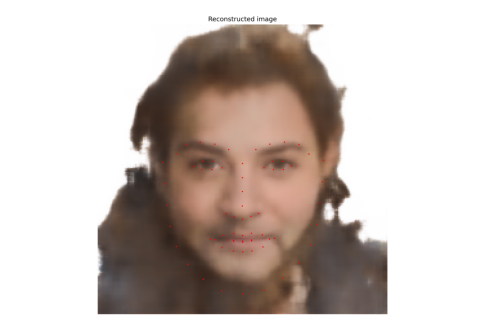

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

img = Image.open("/content/generated_face.png")

plt.figure(figsize=(6,6))
plt.imshow(img)
plt.axis("off")
plt.show()

In [1]:
%cd /content
!git clone https://github.com/SOUHARDGUPTA/Speech-To-Face-Generation-.git

/content
Cloning into 'Speech-To-Face-Generation-'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [3]:
!cp "/content/S2F_final.ipynb" "/content/Speech-To-Face-Generation-/"

cp: cannot stat '/content/S2F_final.ipynb': No such file or directory
